Assignment 1 - Experiment 1

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

In [2]:

tf.config.run_functions_eagerly(True)
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [3]:
from tensorflow.keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

In [4]:
train_images.shape, test_images.shape, test_labels.shape, test_labels.shape

((60000, 28, 28), (10000, 28, 28), (10000,), (10000,))

In [5]:
train_images = train_images.reshape((60000, 28 * 28))
train_images = train_images.astype('float32') / 255

test_images = test_images.reshape((10000, 28 * 28))
test_images = test_images.astype('float32') / 255

In [6]:
val_images, train_images = train_images[:5000], train_images[5000:]
val_labels, train_labels = train_labels[:5000], train_labels[5000:]

In [7]:
from tensorflow.keras import models
from tensorflow.keras import layers

model = models.Sequential()
model.add(layers.Dense(1, activation='relu', input_shape=(28 * 28,)))
model.add(layers.Dense(10, activation='softmax'))

In [ ]:
#keras.utils.plot_model(model, "mnist_model_1hnode.png", show_shapes=True) # plot a graph of the model

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [9]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 1)                 785       
                                                                 
 dense_1 (Dense)             (None, 10)                20        
                                                                 
Total params: 805 (3.14 KB)
Trainable params: 805 (3.14 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [10]:
# For use with non-categorical labels
model.compile(optimizer='rmsprop',
# model.compile(optimizer=keras.optimizers.SGD(lr=1e-3),
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])

In [11]:
epochs = 30
history = model.fit(train_images, train_labels, epochs=epochs,
                    validation_data=(val_images, val_labels))

Epoch 1/30
   9/1719 [..............................] - ETA: 10s - loss: 2.2816 - accuracy: 0.1424 

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 11s 6ms/step - loss: 1.9365 - accuracy: 0.2104 - val_loss: 1.8152 - val_accuracy: 0.2588
Epoch 2/30
1719/1719 [==============================] - 10s 6ms/step - loss: 1.7848 - accuracy: 0.2762 - val_loss: 1.7157 - val_accuracy: 0.3184
Epoch 3/30
1719/1719 [==============================] - 11s 6ms/step - loss: 1.7145 - accuracy: 0.3073 - val_loss: 1.6683 - val_accuracy: 0.3334
Epoch 4/30
1719/1719 [==============================] - 10s 6ms/step - loss: 1.6773 - accuracy: 0.3250 - val_loss: 1.6413 - val_accuracy: 0.3500
Epoch 5/30
1719/1719 [==============================] - 11s 6ms/step - loss: 1.6508 - accuracy: 0.3401 - val_loss: 1.6200 - val_accuracy: 0.3658
Epoch 6/30
1719/1719 [==============================] - 10s 6ms/step - loss: 1.6263 - accuracy: 0.3610 - val_loss: 1.5992 - val_accuracy: 0.3784
Epoch 7/30
1719/1719 [==============================] - 10s 6ms/step - loss: 1.6028 - accuracy: 0.3724 - val_loss: 1.5802 - val_accuracy: 0.3

In [12]:
test_loss, test_acc = model.evaluate(test_images, test_labels)

313/313 [==============================] - 1s 3ms/step - loss: 1.5680 - accuracy: 0.4019


In [13]:
print(f'test acc: {test_acc}, test loss: {test_loss}')

test acc: 0.4018999934196472, test loss: 1.5679899454116821


In [14]:
history_dict = history.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

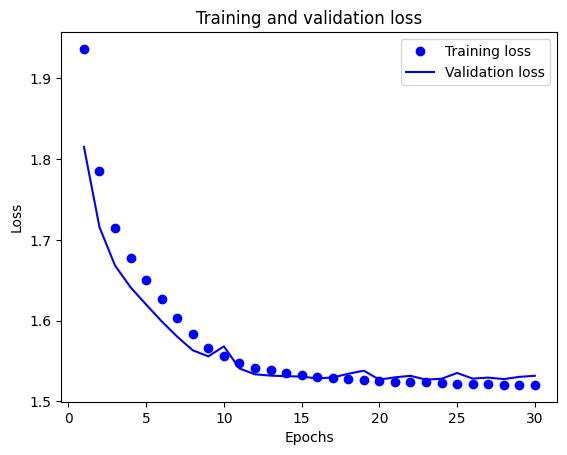

In [15]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

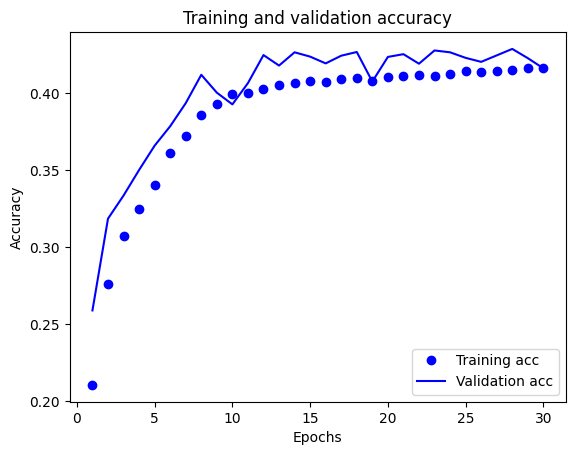

In [16]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [17]:
pred_probs = model.predict(train_images)
pred_classes = np.argmax(pred_probs, axis=1)

 252/1719 [===>..........................] - ETA: 0s

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 1s 575us/step


In [18]:
from sklearn.metrics import confusion_matrix

conf_mx = confusion_matrix(train_labels,pred_classes)
conf_mx

array([[ 120,   22,  400,  147,    1,    0, 4750,    0,    3,    1],
       [   3, 5539,   41,  342,  132,    0,   76,    0,   43,    3],
       [ 135,  208,  889,  752,   35,    0, 3427,    2,   14,    8],
       [  66,  890,  950, 2911,  150,    0,  554,   25,   56,   36],
       [   7, 1111,   46,  162, 3007,    0,   41,   42,    9,  882],
       [  72,  678, 1066, 2581,   58,    0,  421,   37,   49,   25],
       [  60,   15,  223,  109,    2,    0, 5003,    0,    5,    0],
       [   2,  483,   12,   65, 1087,    0,    5, 3546,    2,  513],
       [  28, 1699,  457, 2838,  134,    0,   92,    9,  120,   12],
       [   2,  471,   26,   72, 2022,    0,   14, 1449,    2, 1396]])

In [19]:
def plot_confusion_matrix(matrix):
    """If you prefer color and a colorbar"""
    fig = plt.figure(figsize=(8,8))
    ax = fig.add_subplot(111)
    cax = ax.matshow(matrix)
    fig.colorbar(cax)

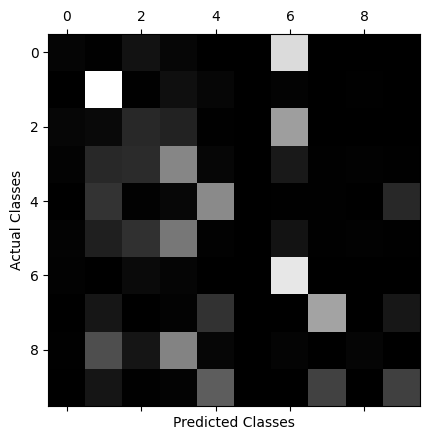

In [20]:
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.xlabel("Predicted Classes")
plt.ylabel("Actual Classes")
#plt.savefig("confusion_matrix_plot_mnist", tight_layout=False)
plt.show()

In [21]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

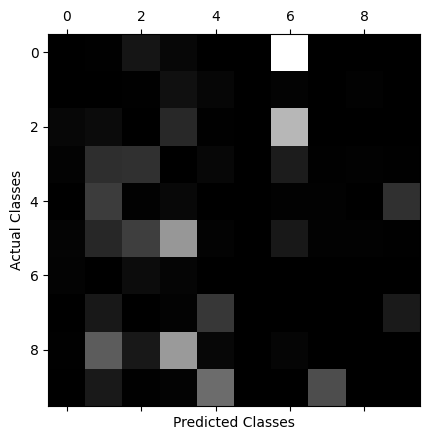

In [22]:
np.fill_diagonal(norm_conf_mx, 0)
plt.matshow(norm_conf_mx, cmap=plt.cm.gray)
plt.xlabel("Predicted Classes")
plt.ylabel("Actual Classes")
#plt.savefig("confusion_matrix_errors_plot_mnist_val", tight_layout=False)
plt.show()

In [23]:
def plot_digits(instances, pos, images_per_row=5, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size,size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        rimages = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(rimages, axis=1))
    image = np.concatenate(row_images, axis=0)
    pos.imshow(image, cmap = 'binary', **options)
    pos.axis("off")

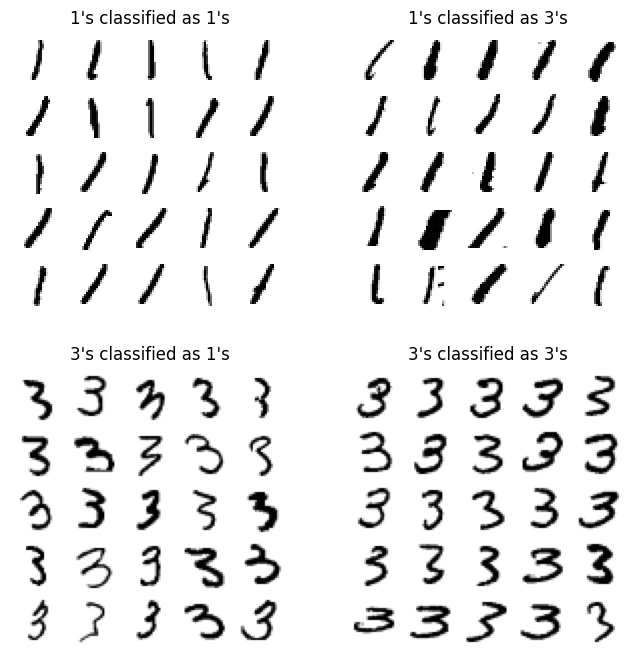

In [24]:
cl_a, cl_b = 1, 3
X_aa = train_images[(train_labels == cl_a) & (pred_classes == cl_a)]
X_ab = train_images[(train_labels == cl_a) & (pred_classes == cl_b)]
X_ba = train_images[(train_labels == cl_b) & (pred_classes == cl_a)]
X_bb = train_images[(train_labels == cl_b) & (pred_classes == cl_b)]

plt.figure(figsize=(8,8))

p1 = plt.subplot(221)
p2 = plt.subplot(222)
p3 = plt.subplot(223)
p4 = plt.subplot(224)

plot_digits(X_aa[:25], p1, images_per_row=5);
plot_digits(X_ab[:25], p2, images_per_row=5);
plot_digits(X_ba[:25], p3, images_per_row=5);
plot_digits(X_bb[:25], p4, images_per_row=5);


p1.set_title(f"{cl_a}'s classified as {cl_a}'s")
p2.set_title(f"{cl_a}'s classified as {cl_b}'s")
p3.set_title(f"{cl_b}'s classified as {cl_a}'s")
p4.set_title(f"{cl_b}'s classified as {cl_b}'s")

# plt.savefig("error_analysis_digits_plot_EXP1_valid")

plt.show()

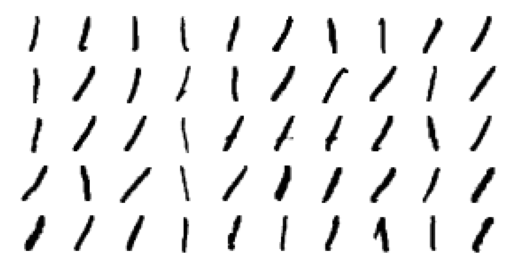

In [25]:
# display 50 of the 1's classified correctly
plot_digits(X_aa[:50],plt,images_per_row = 10)

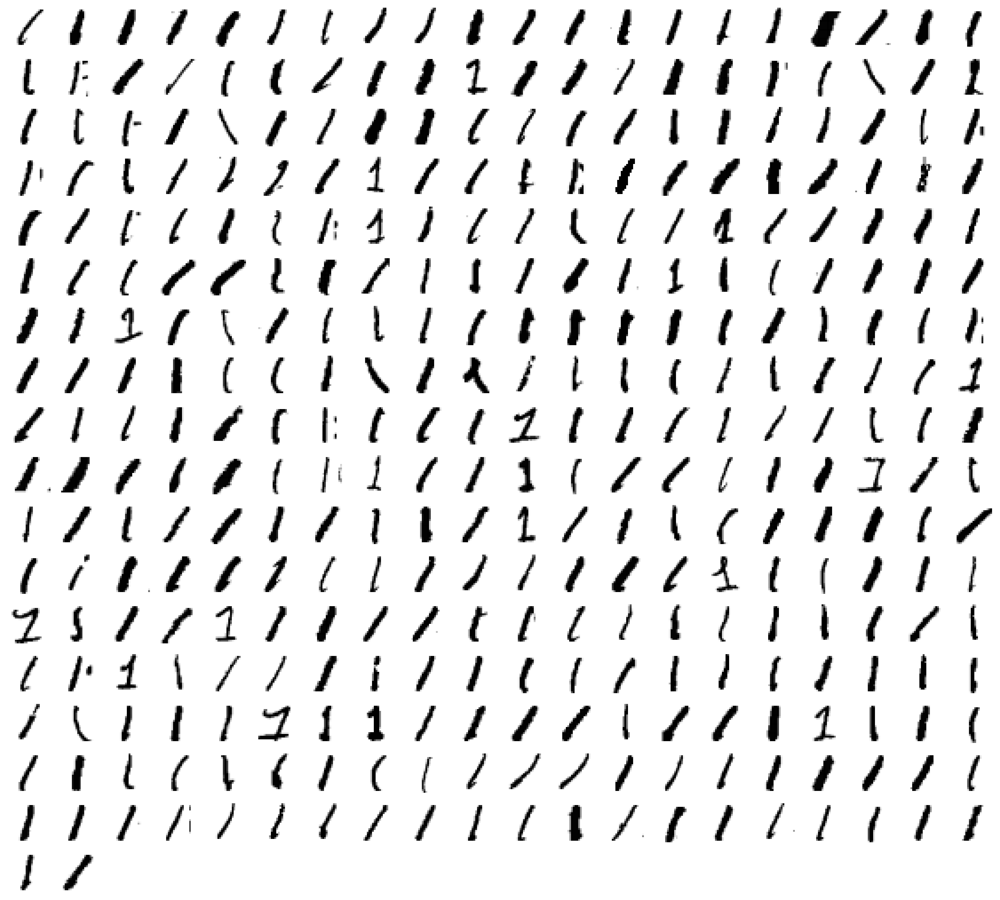

In [26]:
# display all the 1's classified as 3's
num = X_ab.shape[0]
plt.figure(figsize=(50,50))
plot_digits(X_ab[:num],plt, images_per_row = 20)

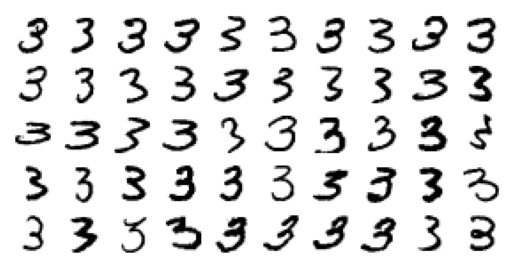

In [27]:
# display 50 of the 3's classified correctly
plot_digits(X_bb[:50],plt, images_per_row = 10)

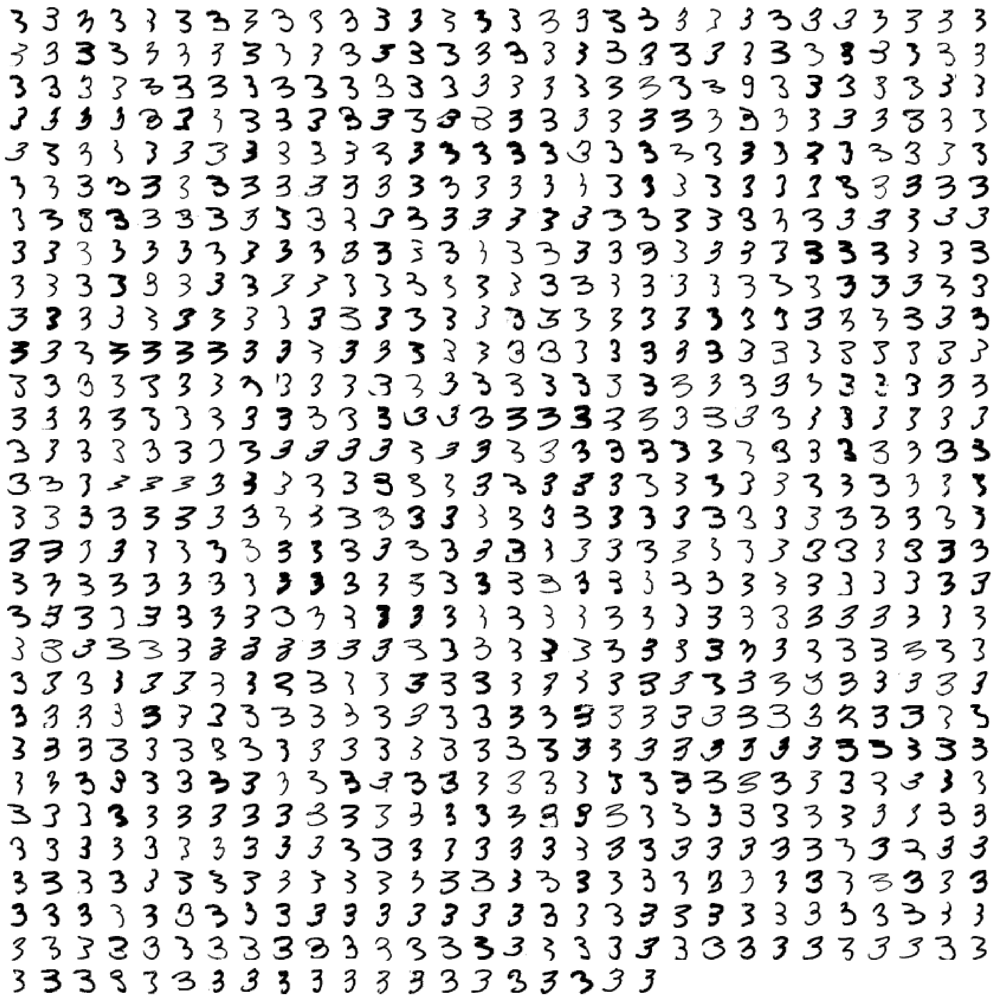

In [28]:
# display all the 3's classified as 1's
num = X_ba.shape[0]
plt.figure(figsize=(50,50))
plot_digits(X_ba[:num],plt, images_per_row = 30)

In [29]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 2 layers


[<KerasTensor: shape=(None, 1) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_1')>]

In [30]:
# Get the output of the hidden node for each of the 55000 training images
activations = activation_model.predict(train_images)
hidden_layer_activation = activations[0]
hidden_layer_activation.shape 

 198/1719 [==>...........................] - ETA: 1s

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 1s 678us/step


(55000, 1)

In [31]:
print(f"The maximum activation value of the hidden node is {hidden_layer_activation.max()}")

The maximum activation value of the hidden node is 57.79374313354492


In [32]:
# Some stats about the output layer as an aside...
np.set_printoptions(suppress = True)  # display probabilities as decimals and NOT in scientific notation
ouput_layer_activation = activations[1]
print(f"The output node has shape {ouput_layer_activation.shape}")
print(f"The output for the first image are {ouput_layer_activation[0].round(4)}")
print(f"The sum of the probabilities is (approximately) {ouput_layer_activation[0].sum()}")

The output node has shape (55000, 10)
The output for the first image are [0.     0.     0.     0.     0.004  0.     0.     0.768  0.     0.2279]
The sum of the probabilities is (approximately) 1.0000001192092896


In [33]:
boxplot_df = pd.DataFrame({'act_value':hidden_layer_activation.reshape(55000),
                           'pred_class':pred_classes})
boxplot_df.head()

,act_value,pred_class
0,16.649752,7
1,1.841570,3
2,4.715554,4
3,0.000000,6
4,2.489548,1


<Axes: title={'center': 'act_value'}, xlabel='pred_class'>

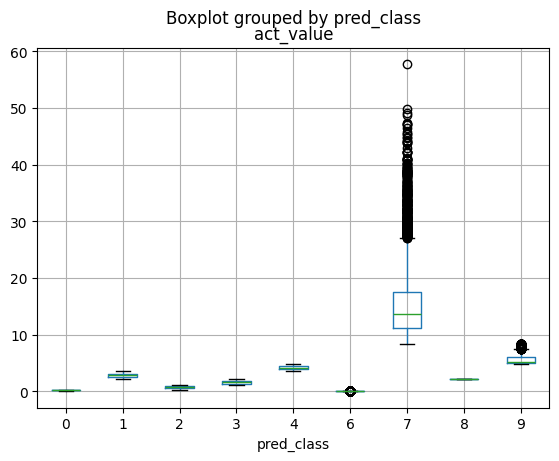

In [ ]:
# To see how closely the hidden nodes activation values correlate with the class predictions
boxplot_df[['act_value','pred_class']].boxplot(by ='pred_class', column =['act_value'], grid = True)

In [37]:
boxplot_df['pred_class'].value_counts() # Another way to verify what the boxplot is telling us

6    14383
1    11116
3     9979
4     6628
7     5110
2     4110
9     2876
0      495
8      303
Name: pred_class, dtype: int64

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/2965432489.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bplot = sns.boxplot(y='act_value', x='pred_class',


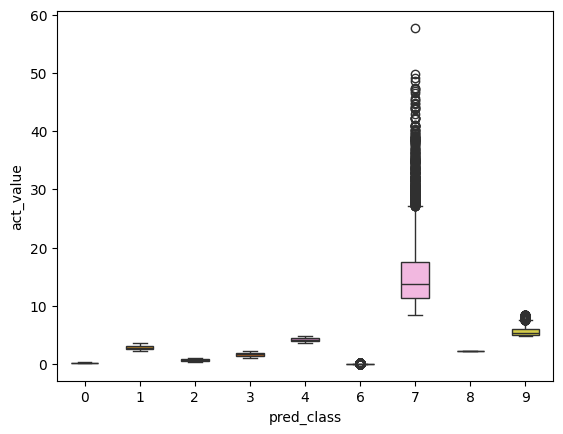

In [36]:
# Let us use seaborn for the boxplots this time.
import seaborn as sns
bplot = sns.boxplot(y='act_value', x='pred_class',
                 data=boxplot_df,
                 width=0.5,
                 palette="colorblind")

Experiment 2 

In [38]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
tf.__version__
tf.config.run_functions_eagerly(True)
import numpy as np
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

In [39]:
from tensorflow.keras import models
from tensorflow.keras import layers

model = models.Sequential()
model.add(layers.Dense(2, activation='relu', input_shape=(28 * 28,)))
model.add(layers.Dense(10, activation='softmax'))

In [40]:
model.compile(optimizer='rmsprop',
#                 loss='categorical_crossentropy',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])

In [41]:
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
   1/1719 [..............................] - ETA: 2:55 - loss: 2.2970 - accuracy: 0.1250

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 11s 6ms/step - loss: 1.5984 - accuracy: 0.4198 - val_loss: 1.3302 - val_accuracy: 0.5516
Epoch 2/30
1719/1719 [==============================] - 11s 6ms/step - loss: 1.2547 - accuracy: 0.5823 - val_loss: 1.1811 - val_accuracy: 0.6144
Epoch 3/30
1719/1719 [==============================] - 11s 6ms/step - loss: 1.1627 - accuracy: 0.6210 - val_loss: 1.1263 - val_accuracy: 0.6528
Epoch 4/30
1719/1719 [==============================] - 11s 7ms/step - loss: 1.1148 - accuracy: 0.6504 - val_loss: 1.0910 - val_accuracy: 0.6764
Epoch 5/30
1719/1719 [==============================] - 11s 7ms/step - loss: 1.0828 - accuracy: 0.6689 - val_loss: 1.0680 - val_accuracy: 0.6914
Epoch 6/30
1719/1719 [==============================] - 11s 6ms/step - loss: 1.0614 - accuracy: 0.6784 - val_loss: 1.0643 - val_accuracy: 0.6880
Epoch 7/30
1719/1719 [==============================] - 11s 6ms/step - loss: 1.0470 - accuracy: 0.6813 - val_loss: 1.0415 - val_accuracy: 0.6

In [42]:
test_loss, test_acc = model.evaluate(test_images, test_labels)

313/313 [==============================] - 1s 3ms/step - loss: 0.9896 - accuracy: 0.7206


In [43]:
print(f'test acc: {test_acc}, test loss: {test_loss}')

test acc: 0.7206000089645386, test loss: 0.9895943403244019


In [44]:
history_dict = history.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

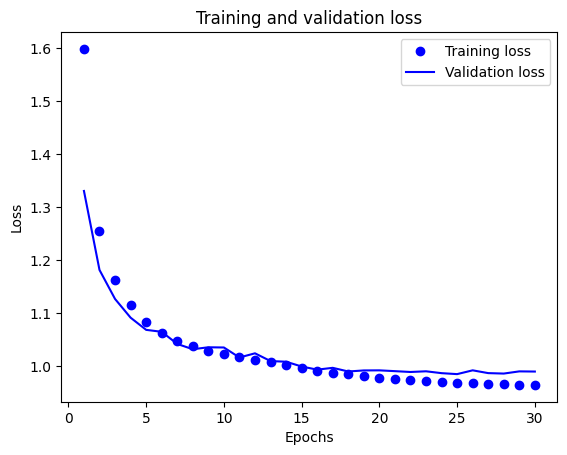

In [45]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

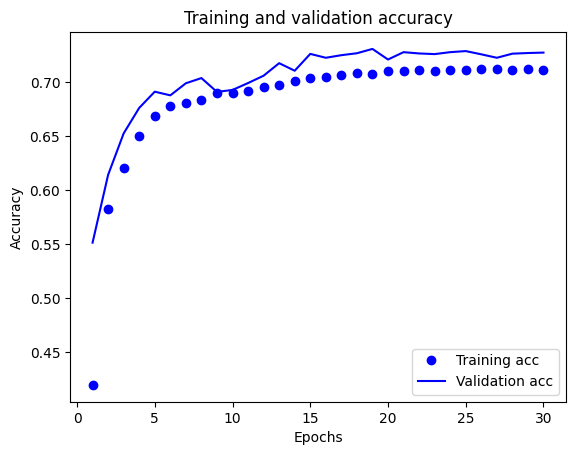

In [46]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [47]:
# Get the predicted classes:
pred_probs = model.predict(train_images)
pred_classes = np.argmax(pred_probs, axis=1)

1719/1719 [==============================] - 1s 595us/step


In [48]:
from sklearn.metrics import confusion_matrix

conf_mx = confusion_matrix(train_labels,pred_classes)
conf_mx

array([[4597,    7,  351,   18,    5,  233,  207,    0,   26,    0],
       [  24, 5732,   16,   66,    8,   28,    2,   52,  219,   32],
       [ 655,   69, 3031,  985,   60,  395,   62,   15,  186,   12],
       [  47,  301,  552, 4106,    5,  149,    6,  230,  226,   16],
       [  15,   57,    5,    4, 4510,   48,  187,    7,   68,  406],
       [ 454,  178,  465,  302,   75, 2318,  249,   49,  868,   29],
       [ 297,    5,    7,    0,   72,  155, 4807,    0,   70,    4],
       [   1,  679,    8,  238,   81,   21,    8, 4257,   46,  376],
       [  84,  843,  179,  588,  124, 1419,  111,   36, 1957,   48],
       [  15,  404,   13,   40,  406,   31,   15,  353,  115, 4062]])

In [49]:
def plot_confusion_matrix(matrix):
    """If you prefer color and a colorbar"""
    fig = plt.figure(figsize=(8,8))
    ax = fig.add_subplot(111)
    cax = ax.matshow(matrix)
    fig.colorbar(cax)

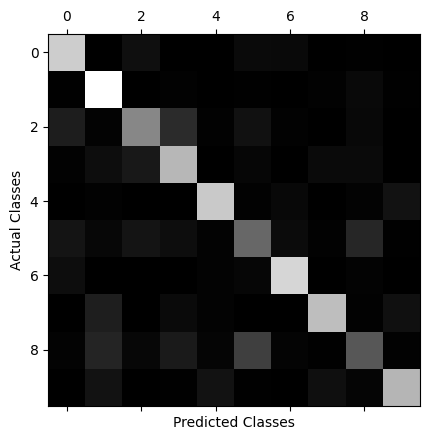

In [50]:
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.xlabel("Predicted Classes")
plt.ylabel("Actual Classes")
# plt.savefig("confusion_matrix_plot_mnist", tight_layout=False)
plt.show()

In [51]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

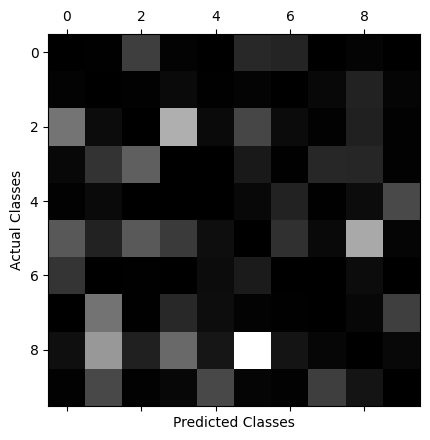

In [52]:
np.fill_diagonal(norm_conf_mx, 0)
plt.matshow(norm_conf_mx, cmap=plt.cm.gray)
plt.xlabel("Predicted Classes")
plt.ylabel("Actual Classes")
# plt.savefig("confusion_matrix_errors_plot_mnist_val", tight_layout=False)
plt.show()

In [53]:
def plot_digits(instances, pos, images_per_row=5, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size,size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        rimages = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(rimages, axis=1))
    image = np.concatenate(row_images, axis=0)
    pos.imshow(image, cmap = 'binary', **options)
    pos.axis("off")

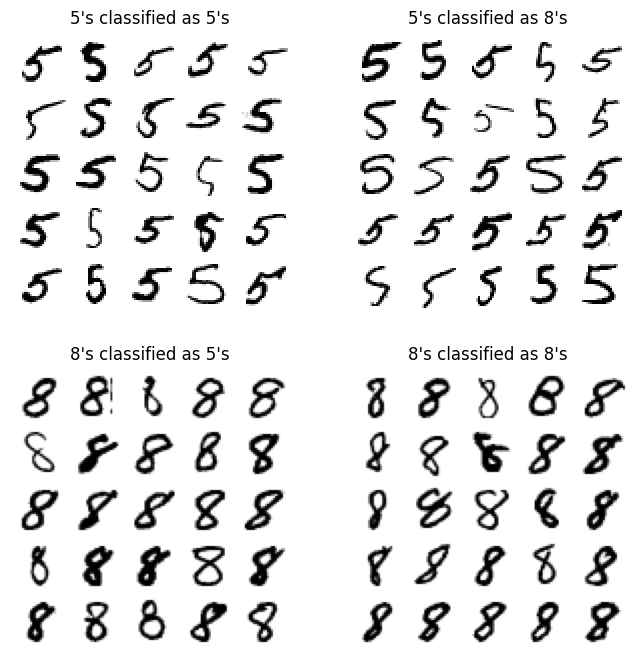

In [54]:
cl_a, cl_b = 5,8
X_aa = train_images[(train_labels == cl_a) & (pred_classes == cl_a)]
X_ab = train_images[(train_labels == cl_a) & (pred_classes == cl_b)]
X_ba = train_images[(train_labels == cl_b) & (pred_classes == cl_a)]
X_bb = train_images[(train_labels == cl_b) & (pred_classes == cl_b)]

plt.figure(figsize=(8,8))

p1 = plt.subplot(221)
p2 = plt.subplot(222)
p3 = plt.subplot(223)
p4 = plt.subplot(224)

plot_digits(X_aa[:25], p1, images_per_row=5);
plot_digits(X_ab[:25], p2, images_per_row=5);
plot_digits(X_ba[:25], p3, images_per_row=5);
plot_digits(X_bb[:25], p4, images_per_row=5);


p1.set_title(f"{cl_a}'s classified as {cl_a}'s")
p2.set_title(f"{cl_a}'s classified as {cl_b}'s")
p3.set_title(f"{cl_b}'s classified as {cl_a}'s")
p4.set_title(f"{cl_b}'s classified as {cl_b}'s")

# plt.savefig("error_analysis_digits_plot_EXP1_valid")

plt.show()

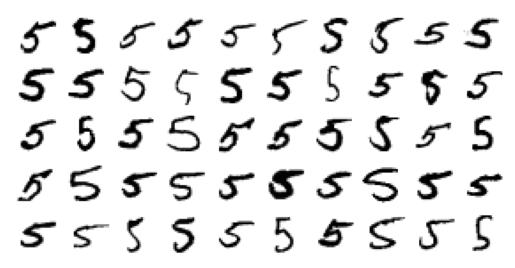

In [55]:
# display 50 of the 5's classified correctly
plot_digits(X_aa[:50],plt,images_per_row = 10)

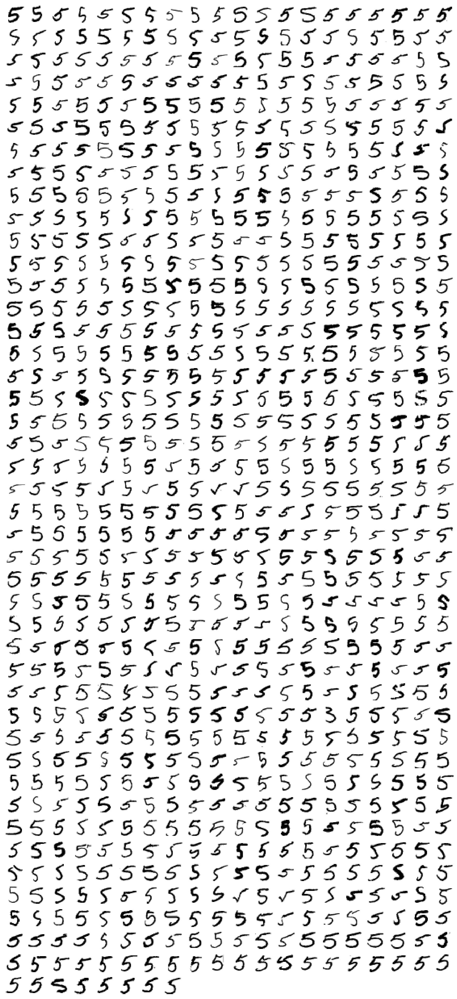

In [56]:
# display all the 5's classified as 8's
num = X_ab.shape[0]
plt.figure(figsize=(50,50))
plot_digits(X_ab[:num],plt, images_per_row = 20)

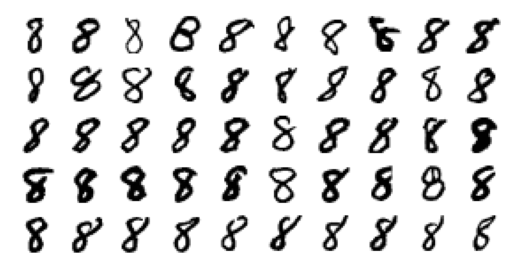

In [57]:
# display 50 of the 8's classified correctly
plot_digits(X_bb[:50],plt, images_per_row = 10)

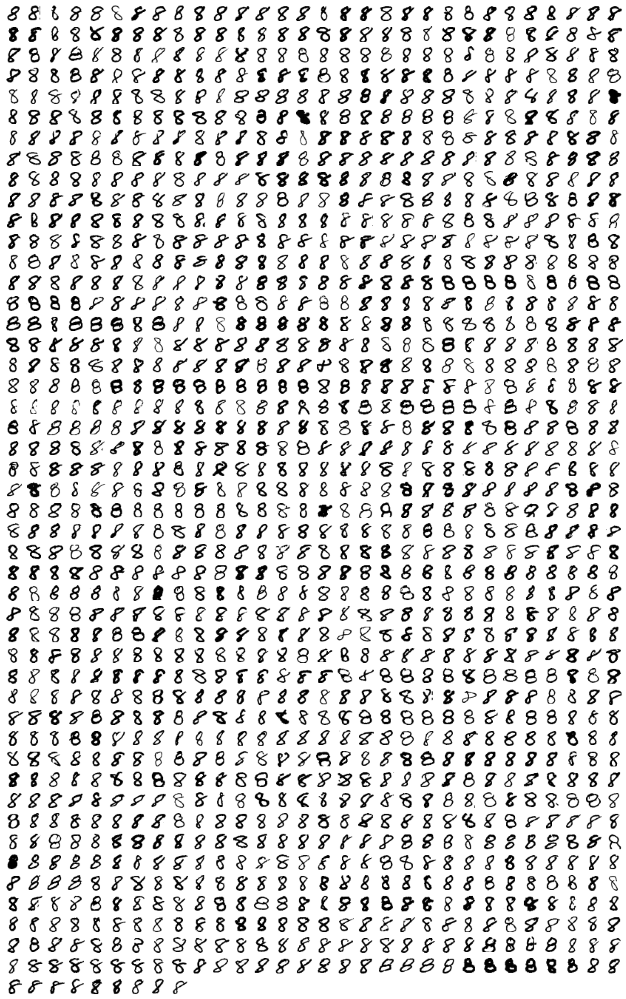

In [58]:
# display all the 8's classified as 5's
num = X_ba.shape[0]
plt.figure(figsize=(50,50))
plot_digits(X_ba[:num],plt, images_per_row = 30)

In [59]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 2 layers


[<KerasTensor: shape=(None, 2) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_1')>]

In [60]:
# Get the output of the hidden node for each of the 55000 training images
activations = activation_model.predict(train_images)
hidden_layer_activation = activations[0]
hidden_layer_activation.shape   #  2 hidden node each has one activation value per training image

 134/1719 [=>............................] - ETA: 1s

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 1s 657us/step


(55000, 2)

In [61]:
hidden_node1_activation = hidden_layer_activation[:,0] # get activation values of the first hidden node
hidden_node2_activation = hidden_layer_activation[:,1] # get activation values of the second hidden node

print(f"The maximum activation value of the first hidden node is {hidden_node1_activation.max()}")
print(f"The maximum activation value of the second hidden node is {hidden_node2_activation.max()}")

The maximum activation value of the first hidden node is 39.945499420166016
The maximum activation value of the second hidden node is 37.226051330566406


In [62]:
# Some stats about the output layer as an aside...
np.set_printoptions(suppress = True)  # display probabilities as decimals and NOT in scientific notation
ouput_layer_activation = activations[1]
print(f"The output node has shape {ouput_layer_activation.shape}")
print(f"The output for the first image are {ouput_layer_activation[0].round(4)}")
print(f"The sum of the probabilities is (approximately) {ouput_layer_activation[0].sum()}")

The output node has shape (55000, 10)
The output for the first image are [0.     0.0039 0.     0.0023 0.     0.     0.     0.9937 0.     0.    ]
The sum of the probabilities is (approximately) 0.9999999403953552


In [63]:
scatterPlot_df =  pd.DataFrame({'act_value_h1':hidden_node1_activation,
                                'act_value_h2':hidden_node2_activation,
                                'pred_class':pred_classes})
scatterPlot_df.head()

,act_value_h1,act_value_h2,pred_class
0,15.563437,15.448370,7
1,12.497601,6.449037,3
2,1.217875,7.001871,9
3,1.425362,0.000000,6
4,5.464718,5.486450,1


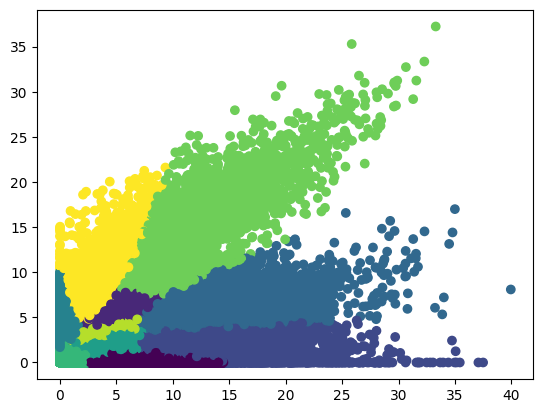

In [64]:
#plt.legend(loc='upper left', prop={'size':6}, bbox_to_anchor=(1,1),ncol=1)
plt.scatter(scatterPlot_df.act_value_h1,
            scatterPlot_df.act_value_h2,
            c=scatterPlot_df.pred_class,
            label=scatterPlot_df.pred_class)
plt.show()

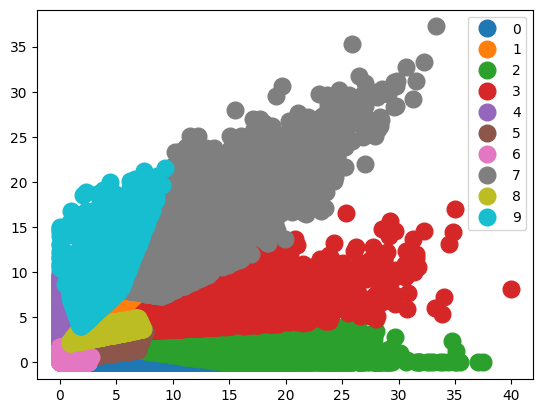

In [65]:
groups = scatterPlot_df.groupby('pred_class')

# Plot
fig, ax = plt.subplots()
ax.margins(0.05) # Optional, just adds 5% padding to the autoscaling
for name, group in groups:
    ax.plot(group.act_value_h1, group.act_value_h2, marker='o', linestyle='', ms=12, label=name)
ax.legend()

plt.show()

Experiment 3 - 3-Layer baseline 

In [69]:
keras.backend.clear_session()
np.random.seed(42)
tf.random.set_seed(42)

from tensorflow.keras import models, layers

model = models.Sequential()
model.add(layers.Dense(32, activation='relu', input_shape=(784,)))
model.add(layers.Dense(16, activation='relu'))
model.add(layers.Dense(8, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.5584 - accuracy: 0.8256 - val_loss: 0.2407 - val_accuracy: 0.9342
Epoch 2/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.2212 - accuracy: 0.9368 - val_loss: 0.1803 - val_accuracy: 0.9516
Epoch 3/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.1719 - accuracy: 0.9510 - val_loss: 0.1467 - val_accuracy: 0.9566
Epoch 4/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.1427 - accuracy: 0.9585 - val_loss: 0.1554 - val_accuracy: 0.9562
Epoch 5/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.1240 - accuracy: 0.9635 - val_loss: 0.1279 - val_accuracy: 0.9660
Epoch 6/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.1086 - accuracy: 0.9678 - val_loss: 0.1462 - val_accuracy: 0.9586
Epoch 7/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.0971 - accuracy: 0.9709 - val_loss: 0.1486 - val_ac

In [71]:
test_loss, test_acc = model.evaluate(test_images, test_labels)

313/313 [==============================] - 1s 3ms/step - loss: 0.1943 - accuracy: 0.9630


In [72]:
print(f'test acc: {test_acc}, test loss: {test_loss}')

test acc: 0.9629999995231628, test loss: 0.19431211054325104


In [73]:
history_dict = history.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

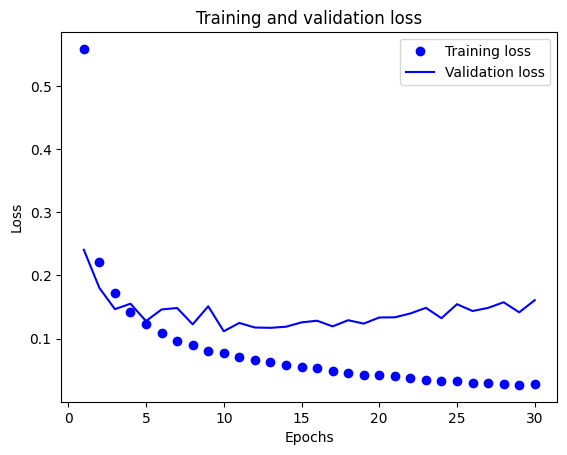

In [74]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

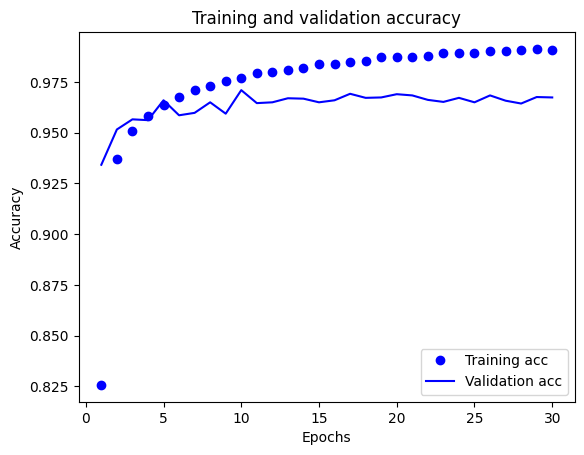

In [75]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [89]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 4 layers


[<KerasTensor: shape=(None, 32) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 16) dtype=float32 (created by layer 'dense_1')>,
 <KerasTensor: shape=(None, 8) dtype=float32 (created by layer 'dense_2')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_3')>]

There are 4 layers in the model.
 126/1719 [=>............................] - ETA: 1s

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 2s 1ms/step

🔍 Layer 1 - dense: shape (55000, 32)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


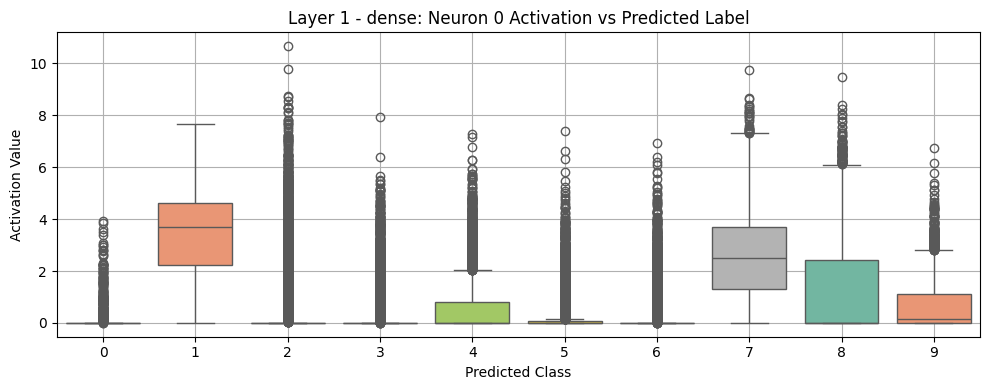

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


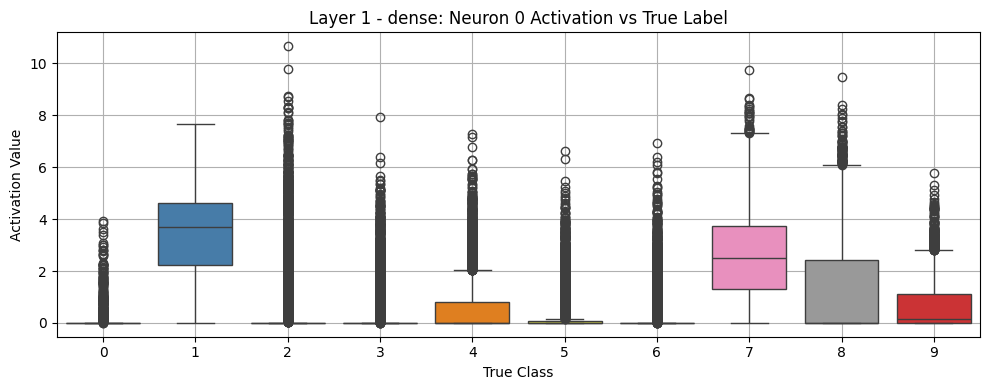


🔍 Layer 2 - dense_1: shape (55000, 16)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


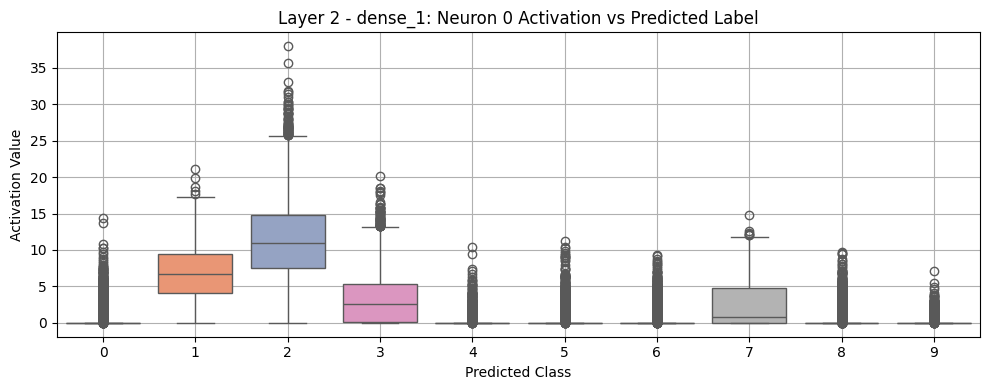

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


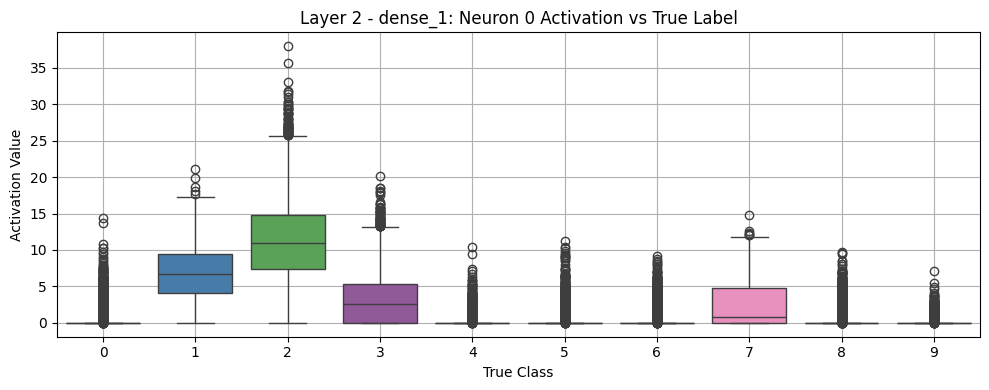

Skipping output layer: dense_2 (shape (55000, 8))
Skipping output layer: dense_3 (shape (55000, 10))


In [90]:
from tensorflow.keras import models
from tensorflow.keras.models import Model
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set this to your actual training data
# train_images = ...
# train_labels = ...

# If train_labels is one-hot, convert to integers
if train_labels.ndim > 1:
    true_labels = np.argmax(train_labels, axis=1)
else:
    true_labels = train_labels

# Create a model that outputs all layers
layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers in the model.")

# Get the activations for each layer (list of arrays)
activations = activation_model.predict(train_images)

# Get final predictions
pred_classes = model.predict(train_images).argmax(axis=1)

# Loop over each layer and generate boxplot for neuron 0
for i, activation in enumerate(activations):
    layer_name = model.layers[i].name
    layer_output = activation

    # Skip if output is 2D (final softmax layer) or has only 10 units
    if layer_output.shape[1] <= 10:
        print(f"Skipping output layer: {layer_name} (shape {layer_output.shape})")
        continue

    print(f"\n🔍 Layer {i+1} - {layer_name}: shape {layer_output.shape}")
    neuron_0_activation = layer_output[:, 0]  # Only neuron 0

    # Build DataFrame comparing neuron output vs both predicted & true class
    boxplot_df = pd.DataFrame({
        'act_value': neuron_0_activation,
        'predicted_label': pred_classes,
        'true_label': true_labels
    })

    # Plot 1: Grouped by predicted label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs Predicted Label')
    plt.xlabel('Predicted Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot 2: Grouped by true label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs True Label')
    plt.xlabel('True Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Experiment 4 - 3 Layers with Tanh

In [91]:
keras.backend.clear_session()
model = models.Sequential()
model.add(layers.Dense(64, activation='tanh', input_shape=(784,)))
model.add(layers.Dense(32, activation='tanh'))
model.add(layers.Dense(16, activation='tanh'))
model.add(layers.Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
   1/1719 [..............................] - ETA: 2:19 - loss: 2.3777 - accuracy: 0.0625

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 13s 7ms/step - loss: 0.3696 - accuracy: 0.9042 - val_loss: 0.1802 - val_accuracy: 0.9484
Epoch 2/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.1518 - accuracy: 0.9562 - val_loss: 0.1317 - val_accuracy: 0.9590
Epoch 3/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.1076 - accuracy: 0.9679 - val_loss: 0.1033 - val_accuracy: 0.9710
Epoch 4/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.0824 - accuracy: 0.9757 - val_loss: 0.1120 - val_accuracy: 0.9682
Epoch 5/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.0685 - accuracy: 0.9794 - val_loss: 0.1006 - val_accuracy: 0.9714
Epoch 6/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.0578 - accuracy: 0.9823 - val_loss: 0.1012 - val_accuracy: 0.9716
Epoch 7/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.0484 - accuracy: 0.9852 - val_loss: 0.1063 - val_accuracy: 0.9

In [92]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'test acc: {test_acc}, test loss: {test_loss}')
history_dict = history.history
history_dict.keys()


313/313 [==============================] - 1s 3ms/step - loss: 0.1402 - accuracy: 0.9718
test acc: 0.9718000292778015, test loss: 0.14019660651683807


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

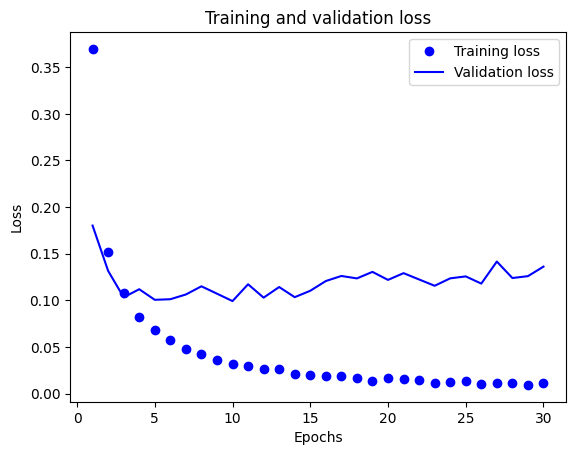

In [93]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

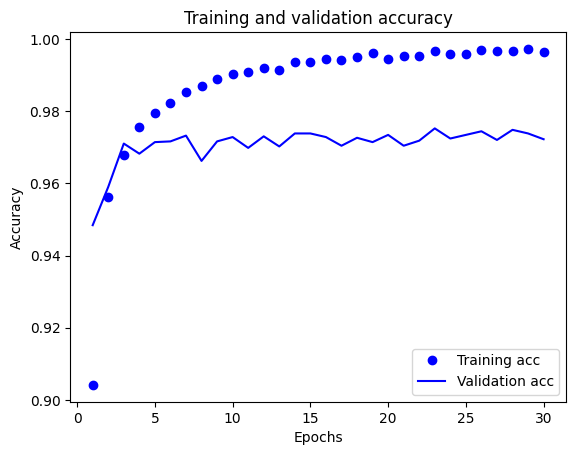

In [94]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [95]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 4 layers


[<KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 32) dtype=float32 (created by layer 'dense_1')>,
 <KerasTensor: shape=(None, 16) dtype=float32 (created by layer 'dense_2')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_3')>]

There are 4 layers in the model.
1719/1719 [==============================] - 2s 1ms/step

🔍 Layer 1 - dense: shape (55000, 64)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


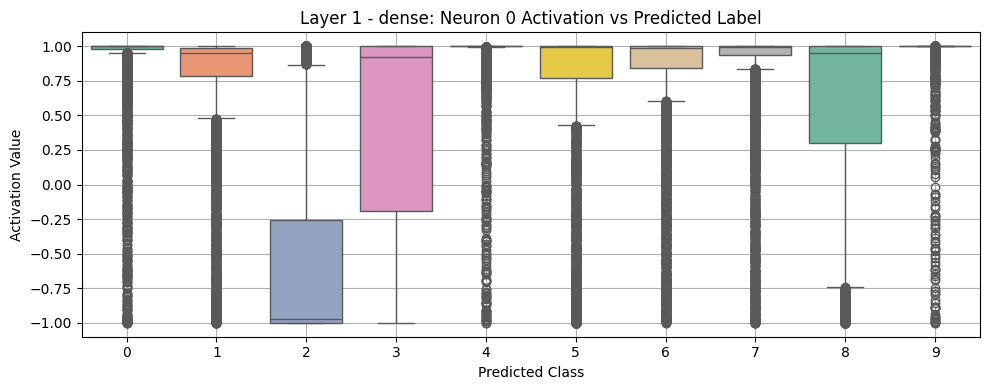

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


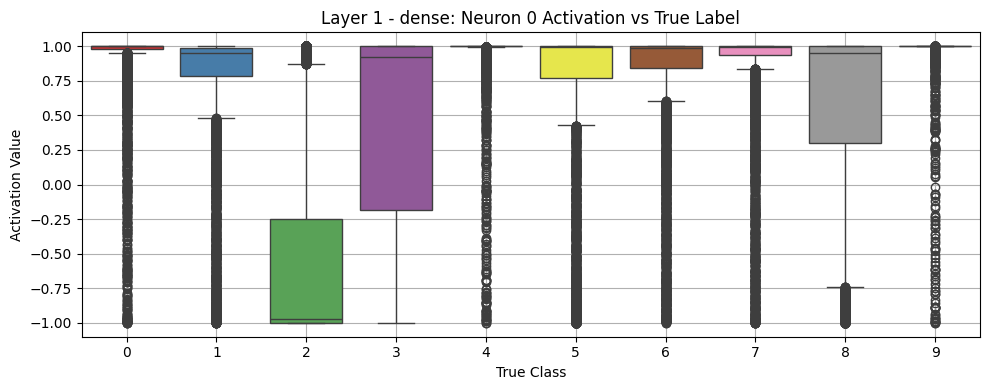


🔍 Layer 2 - dense_1: shape (55000, 32)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


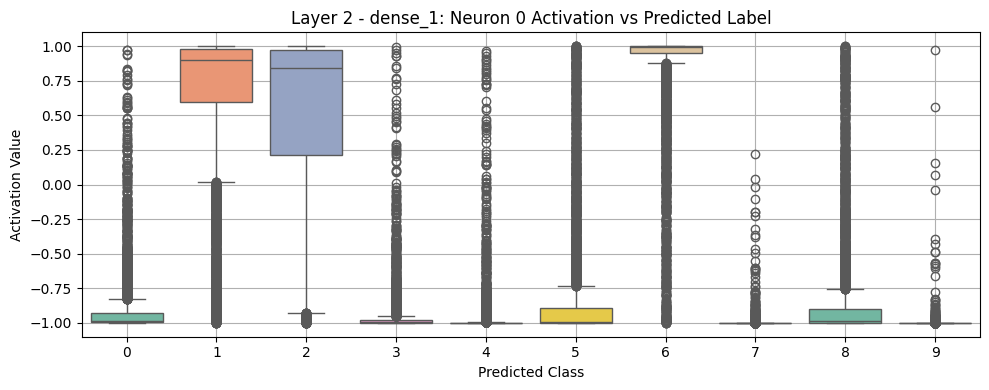

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


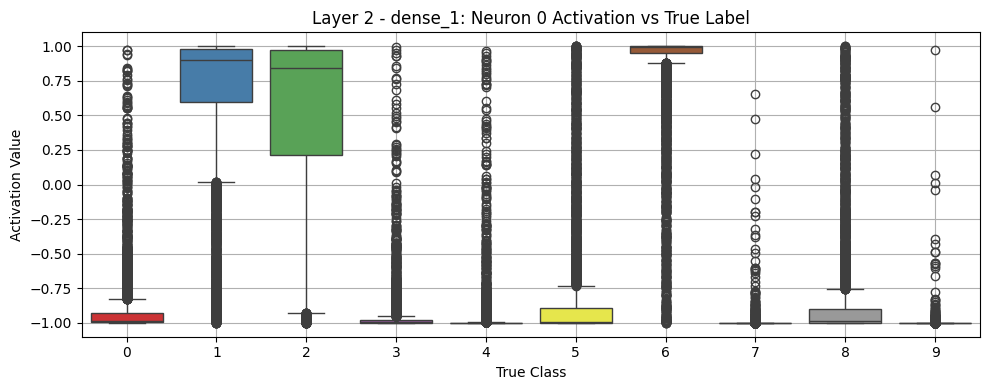

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 3 - dense_2: shape (55000, 16)


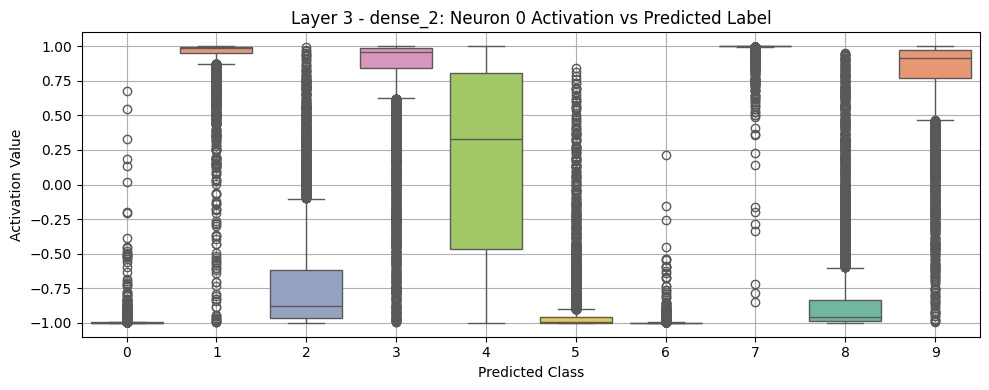

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


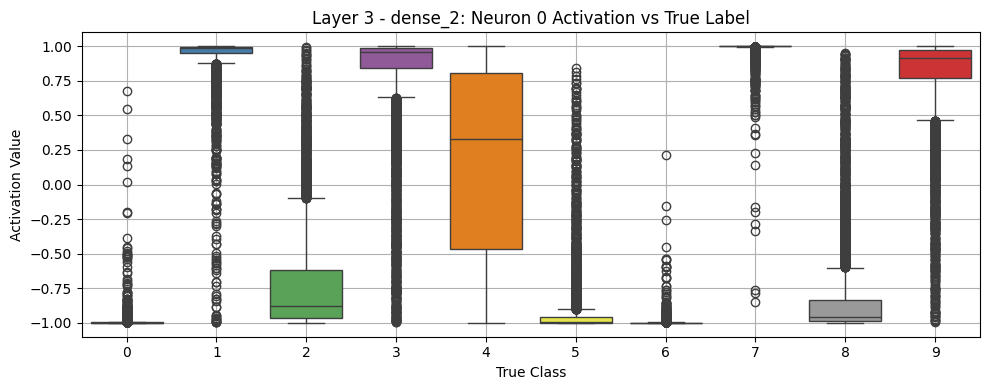

Skipping output layer: dense_3 (shape (55000, 10))


In [96]:
from tensorflow.keras import models
from tensorflow.keras.models import Model
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set this to your actual training data
# train_images = ...
# train_labels = ...

# If train_labels is one-hot, convert to integers
if train_labels.ndim > 1:
    true_labels = np.argmax(train_labels, axis=1)
else:
    true_labels = train_labels

# Create a model that outputs all layers
layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers in the model.")

# Get the activations for each layer (list of arrays)
activations = activation_model.predict(train_images)

# Get final predictions
pred_classes = model.predict(train_images).argmax(axis=1)

# Loop over each layer and generate boxplot for neuron 0
for i, activation in enumerate(activations):
    layer_name = model.layers[i].name
    layer_output = activation

    # Skip if output is 2D (final softmax layer) or has only 10 units
    if layer_output.shape[1] <= 10:
        print(f"Skipping output layer: {layer_name} (shape {layer_output.shape})")
        continue

    print(f"\n🔍 Layer {i+1} - {layer_name}: shape {layer_output.shape}")
    neuron_0_activation = layer_output[:, 0]  # Only neuron 0

    # Build DataFrame comparing neuron output vs both predicted & true class
    boxplot_df = pd.DataFrame({
        'act_value': neuron_0_activation,
        'predicted_label': pred_classes,
        'true_label': true_labels
    })

    # Plot 1: Grouped by predicted label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs Predicted Label')
    plt.xlabel('Predicted Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot 2: Grouped by true label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs True Label')
    plt.xlabel('True Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Experiment 5 Deep ReLU + Batch Normalization

In [97]:
keras.backend.clear_session()
model = models.Sequential()
model.add(layers.Dense(128, activation='relu', input_shape=(784,)))
model.add(layers.BatchNormalization())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(32, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
   5/1719 [..............................] - ETA: 25s - loss: 2.7145 - accuracy: 0.1813 

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 26s 15ms/step - loss: 0.3044 - accuracy: 0.9104 - val_loss: 0.1364 - val_accuracy: 0.9588
Epoch 2/30
1719/1719 [==============================] - 24s 14ms/step - loss: 0.1467 - accuracy: 0.9542 - val_loss: 0.1105 - val_accuracy: 0.9670
Epoch 3/30
1719/1719 [==============================] - 24s 14ms/step - loss: 0.1098 - accuracy: 0.9661 - val_loss: 0.0998 - val_accuracy: 0.9672
Epoch 4/30
1719/1719 [==============================] - 23s 14ms/step - loss: 0.0923 - accuracy: 0.9705 - val_loss: 0.0842 - val_accuracy: 0.9756
Epoch 5/30
1719/1719 [==============================] - 22s 13ms/step - loss: 0.0775 - accuracy: 0.9746 - val_loss: 0.0802 - val_accuracy: 0.9774
Epoch 6/30
1719/1719 [==============================] - 22s 13ms/step - loss: 0.0683 - accuracy: 0.9779 - val_loss: 0.0793 - val_accuracy: 0.9784
Epoch 7/30
1719/1719 [==============================] - 22s 13ms/step - loss: 0.0602 - accuracy: 0.9805 - val_loss: 0.0856 - val_accura

In [98]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'test acc: {test_acc}, test loss: {test_loss}')
history_dict = history.history
history_dict.keys()

313/313 [==============================] - 1s 4ms/step - loss: 0.0787 - accuracy: 0.9808
test acc: 0.9807999730110168, test loss: 0.07871042191982269


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

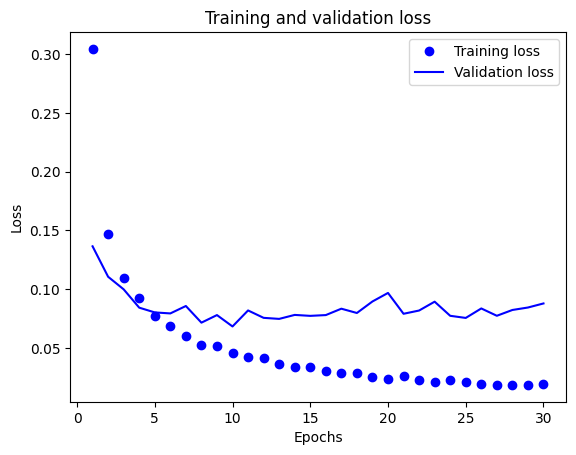

In [99]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

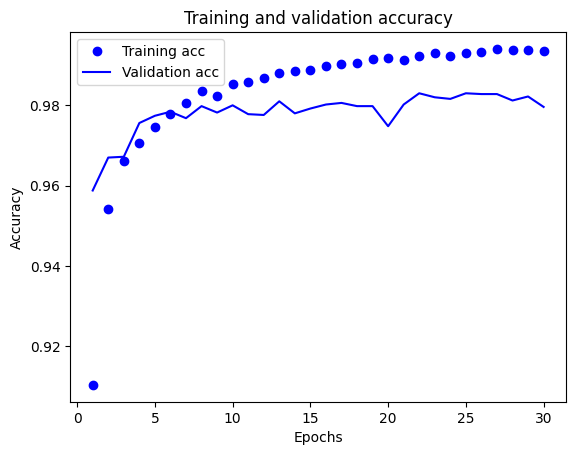

In [100]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [101]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 7 layers


[<KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'batch_normalization')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense_1')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'batch_normalization_1')>,
 <KerasTensor: shape=(None, 32) dtype=float32 (created by layer 'dense_2')>,
 <KerasTensor: shape=(None, 32) dtype=float32 (created by layer 'batch_normalization_2')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_3')>]

There are 7 layers in the model.
1719/1719 [==============================] - 4s 2ms/step

🔍 Layer 1 - dense: shape (55000, 128)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


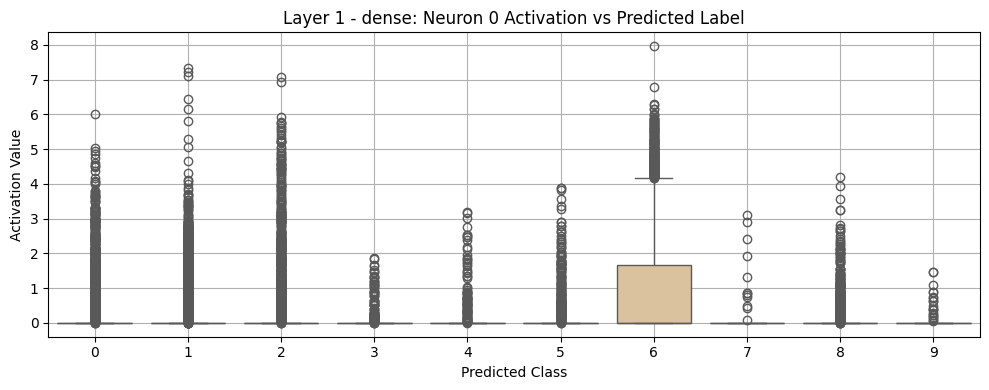

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


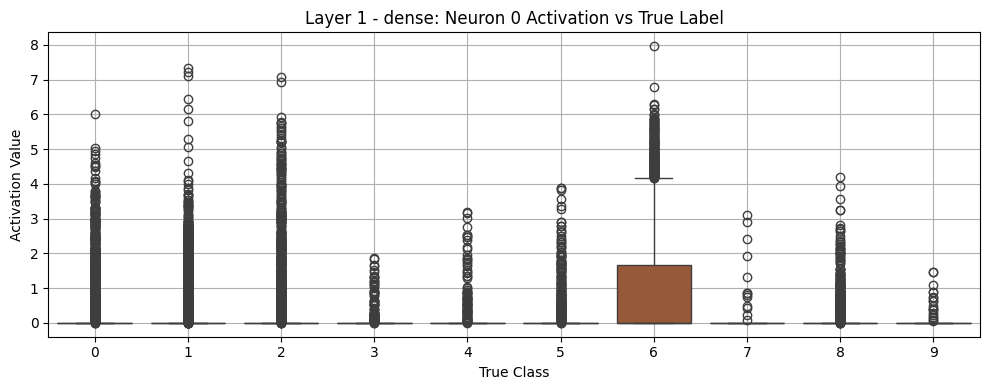

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 2 - batch_normalization: shape (55000, 128)


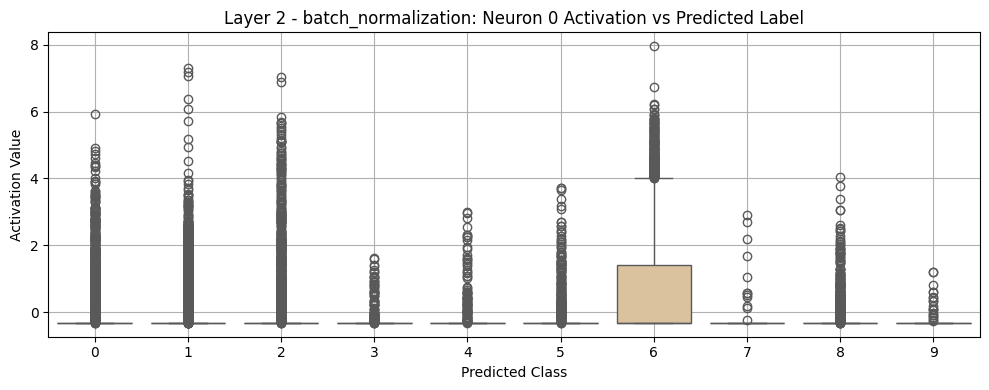

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


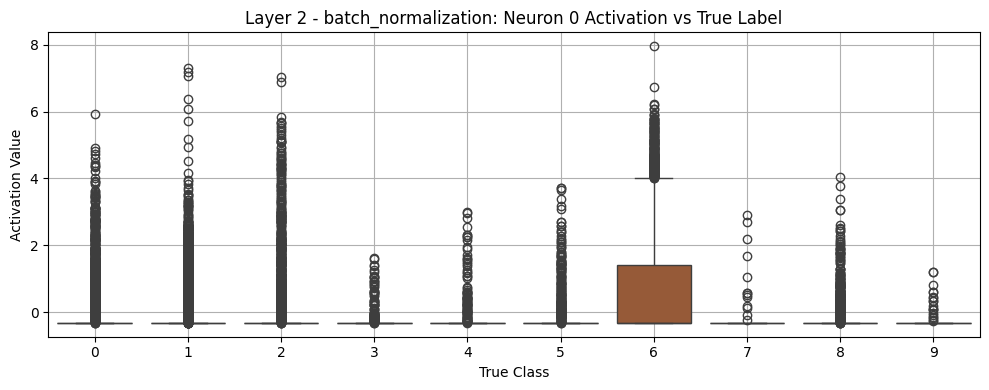

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 3 - dense_1: shape (55000, 64)


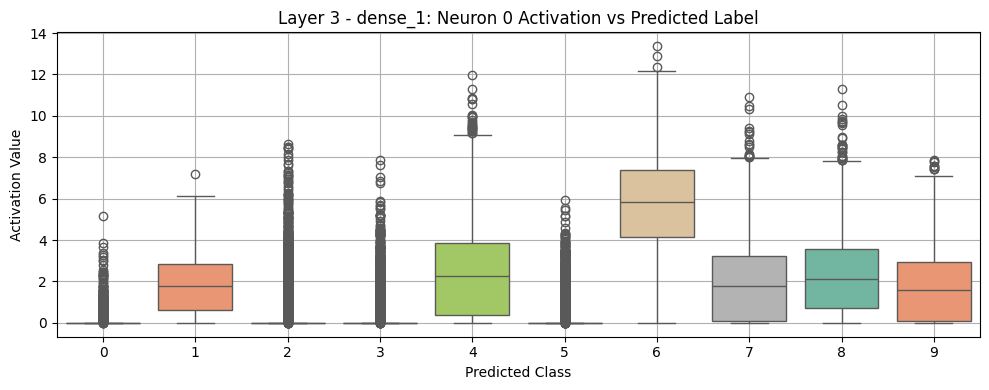

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


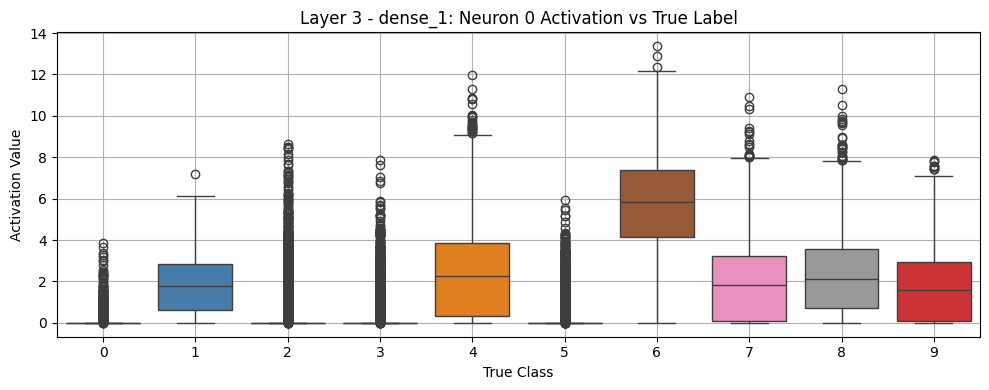

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 4 - batch_normalization_1: shape (55000, 64)


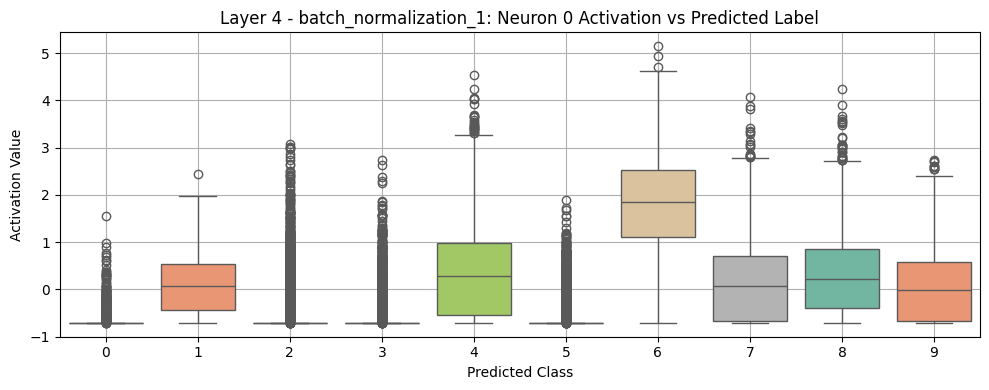

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


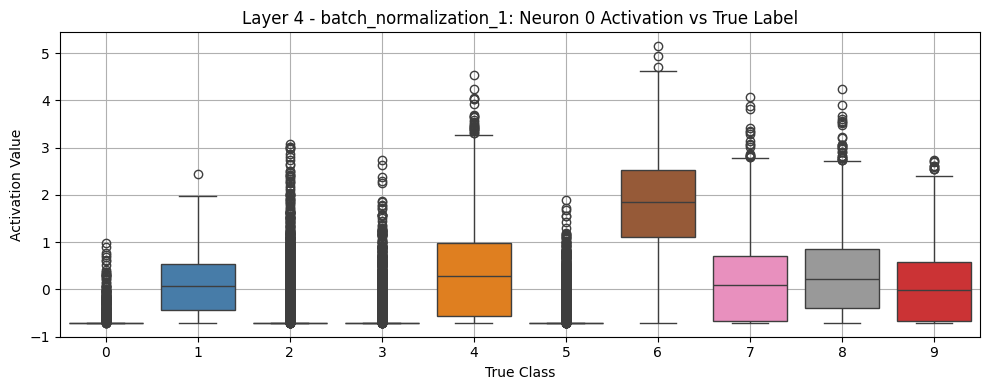

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 5 - dense_2: shape (55000, 32)


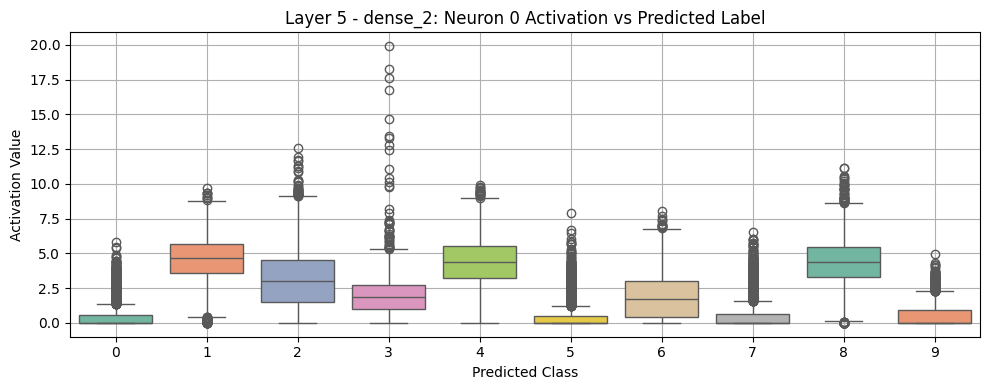

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


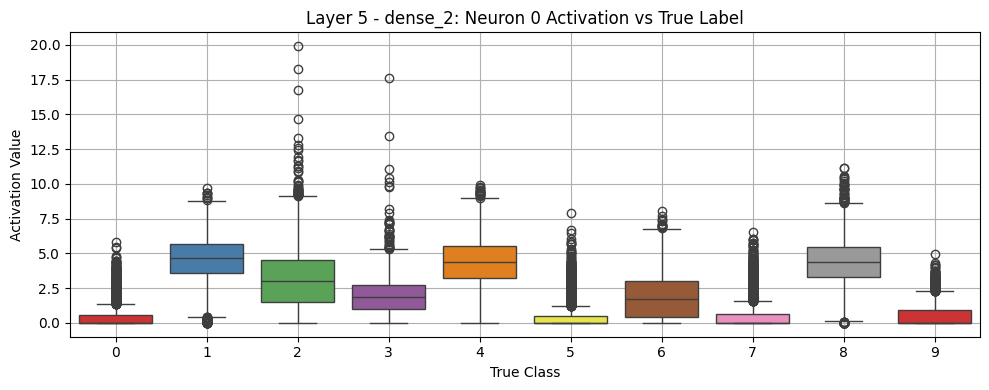

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 6 - batch_normalization_2: shape (55000, 32)


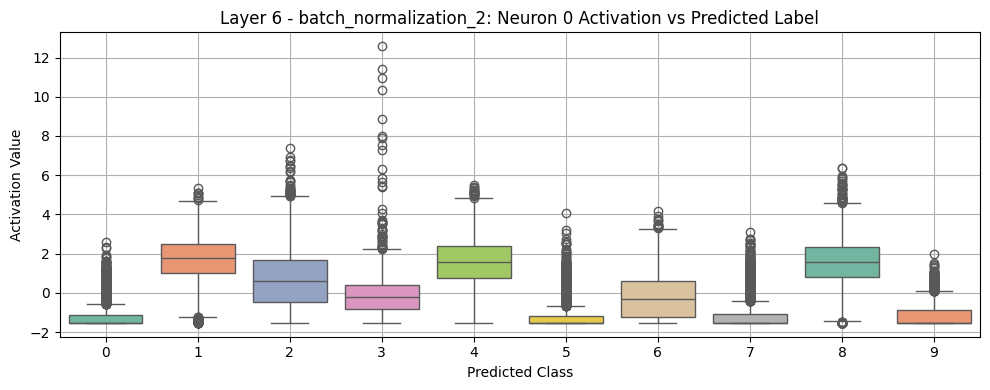

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


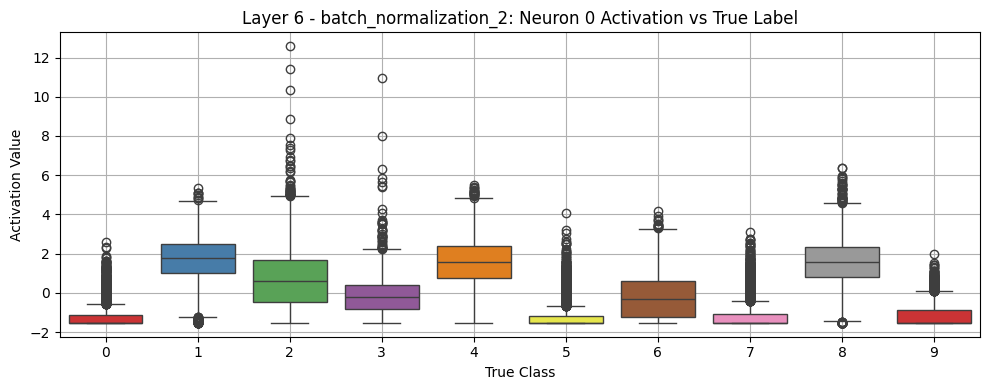

Skipping output layer: dense_3 (shape (55000, 10))


In [102]:
from tensorflow.keras import models
from tensorflow.keras.models import Model
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set this to your actual training data
# train_images = ...
# train_labels = ...

# If train_labels is one-hot, convert to integers
if train_labels.ndim > 1:
    true_labels = np.argmax(train_labels, axis=1)
else:
    true_labels = train_labels

# Create a model that outputs all layers
layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers in the model.")

# Get the activations for each layer (list of arrays)
activations = activation_model.predict(train_images)

# Get final predictions
pred_classes = model.predict(train_images).argmax(axis=1)

# Loop over each layer and generate boxplot for neuron 0
for i, activation in enumerate(activations):
    layer_name = model.layers[i].name
    layer_output = activation

    # Skip if output is 2D (final softmax layer) or has only 10 units
    if layer_output.shape[1] <= 10:
        print(f"Skipping output layer: {layer_name} (shape {layer_output.shape})")
        continue

    print(f"\n🔍 Layer {i+1} - {layer_name}: shape {layer_output.shape}")
    neuron_0_activation = layer_output[:, 0]  # Only neuron 0

    # Build DataFrame comparing neuron output vs both predicted & true class
    boxplot_df = pd.DataFrame({
        'act_value': neuron_0_activation,
        'predicted_label': pred_classes,
        'true_label': true_labels
    })

    # Plot 1: Grouped by predicted label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs Predicted Label')
    plt.xlabel('Predicted Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot 2: Grouped by true label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs True Label')
    plt.xlabel('True Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Experiment 6 Deep Network + Dropout

In [103]:
keras.backend.clear_session()
model = models.Sequential()
model.add(layers.Dense(128, activation='relu', input_shape=(784,)))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
  13/1719 [..............................] - ETA: 15s - loss: 2.2610 - accuracy: 0.1851

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 17s 10ms/step - loss: 0.4497 - accuracy: 0.8634 - val_loss: 0.1625 - val_accuracy: 0.9542
Epoch 2/30
1719/1719 [==============================] - 16s 9ms/step - loss: 0.2224 - accuracy: 0.9349 - val_loss: 0.1251 - val_accuracy: 0.9632
Epoch 3/30
1719/1719 [==============================] - 16s 9ms/step - loss: 0.1771 - accuracy: 0.9479 - val_loss: 0.0995 - val_accuracy: 0.9714
Epoch 4/30
1719/1719 [==============================] - 16s 9ms/step - loss: 0.1544 - accuracy: 0.9547 - val_loss: 0.1005 - val_accuracy: 0.9702
Epoch 5/30
1719/1719 [==============================] - 16s 9ms/step - loss: 0.1366 - accuracy: 0.9601 - val_loss: 0.0932 - val_accuracy: 0.9734
Epoch 6/30
1719/1719 [==============================] - 15s 9ms/step - loss: 0.1265 - accuracy: 0.9624 - val_loss: 0.0855 - val_accuracy: 0.9752
Epoch 7/30
1719/1719 [==============================] - 16s 9ms/step - loss: 0.1183 - accuracy: 0.9651 - val_loss: 0.0943 - val_accuracy: 0.

In [104]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'test acc: {test_acc}, test loss: {test_loss}')
history_dict = history.history
history_dict.keys()

313/313 [==============================] - 1s 3ms/step - loss: 0.0808 - accuracy: 0.9790
test acc: 0.9789999723434448, test loss: 0.08083606511354446


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

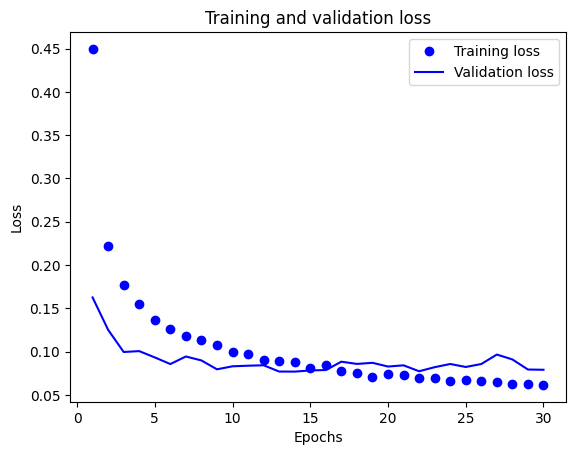

In [105]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

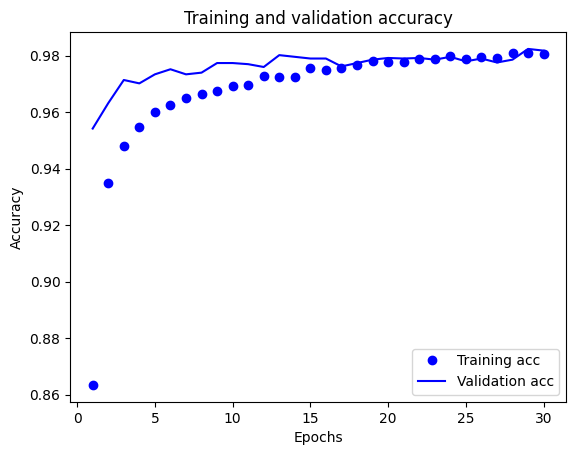

In [106]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [107]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 6 layers


[<KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'dropout')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense_1')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dropout_1')>,
 <KerasTensor: shape=(None, 32) dtype=float32 (created by layer 'dense_2')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_3')>]

There are 6 layers in the model.
1719/1719 [==============================] - 2s 1ms/step

🔍 Layer 1 - dense: shape (55000, 128)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


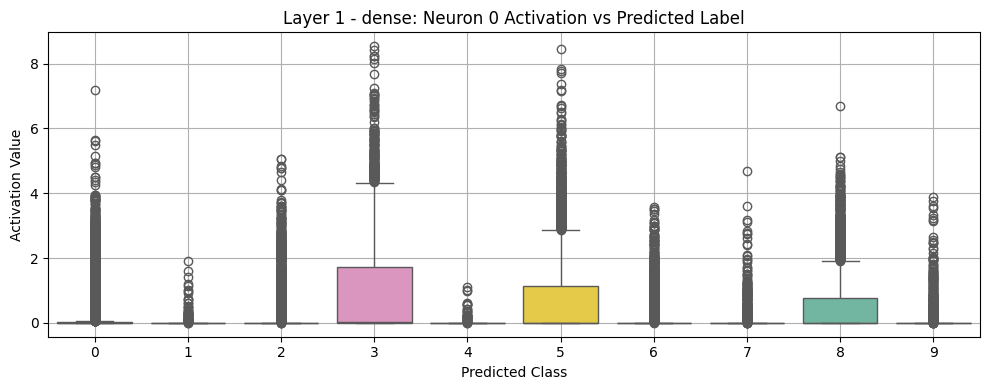

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


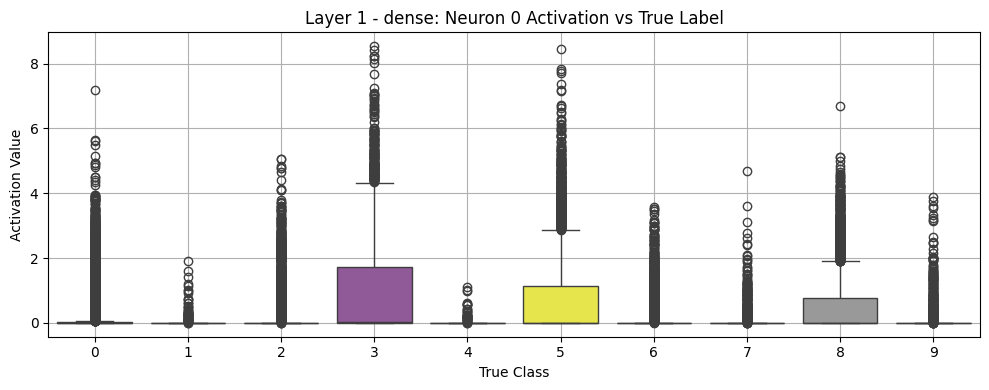

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 2 - dropout: shape (55000, 128)


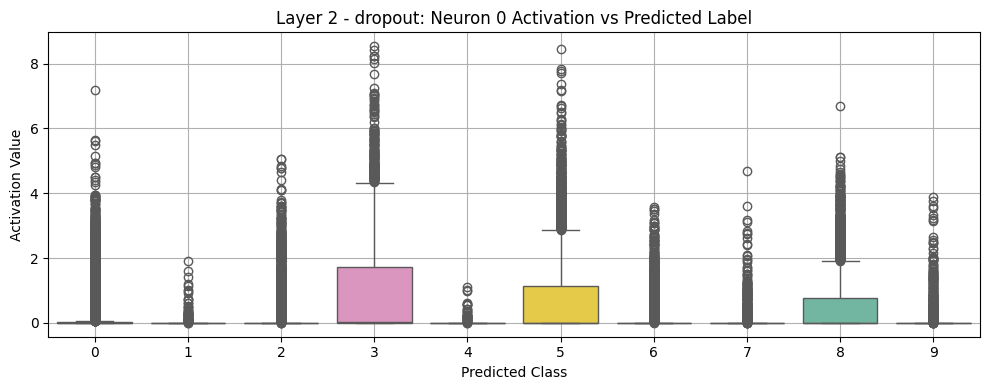

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


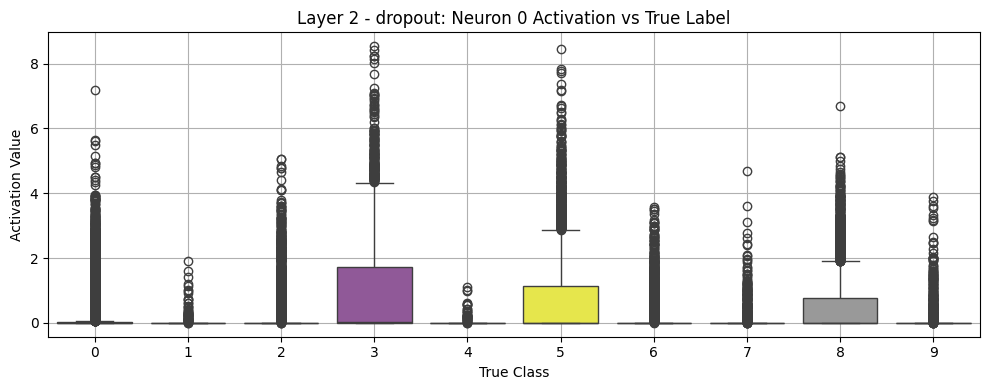

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 3 - dense_1: shape (55000, 64)


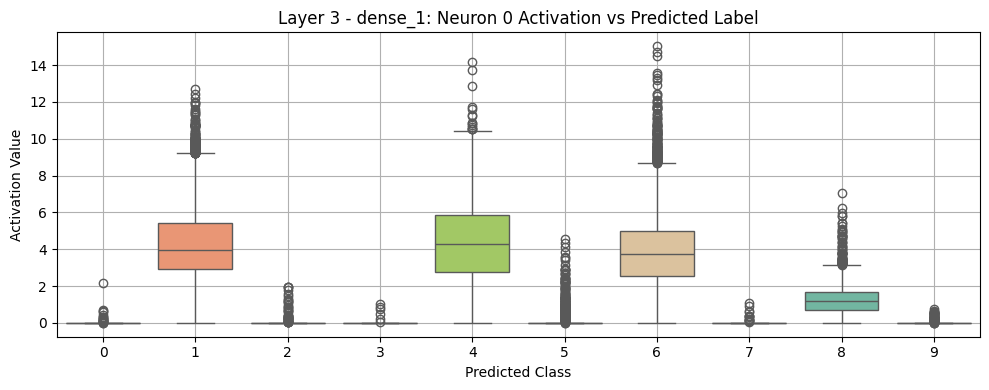

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


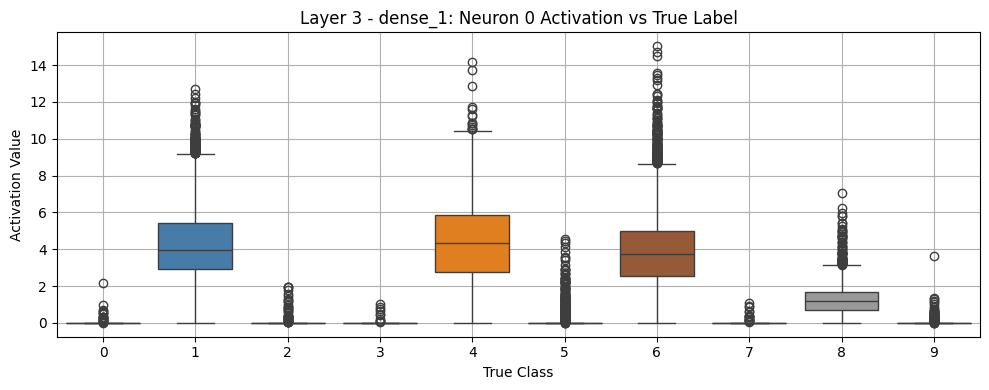

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 4 - dropout_1: shape (55000, 64)


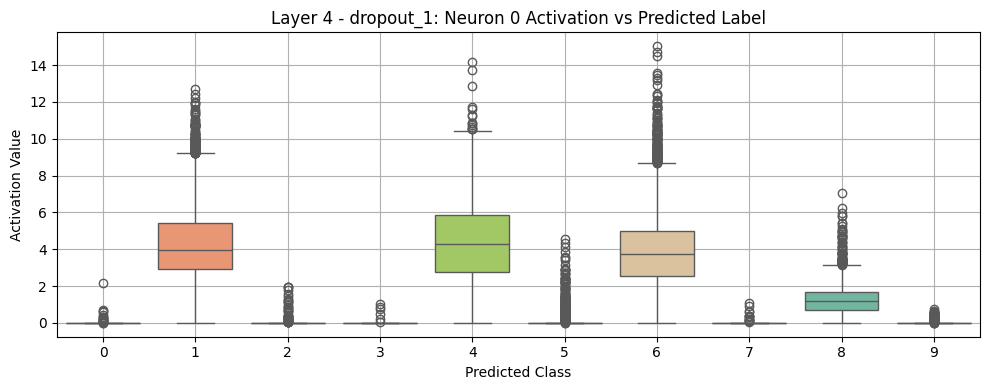

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


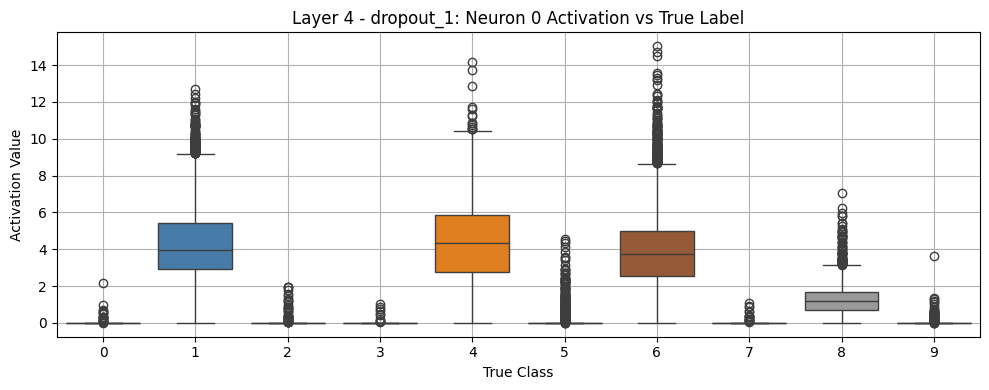

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 5 - dense_2: shape (55000, 32)


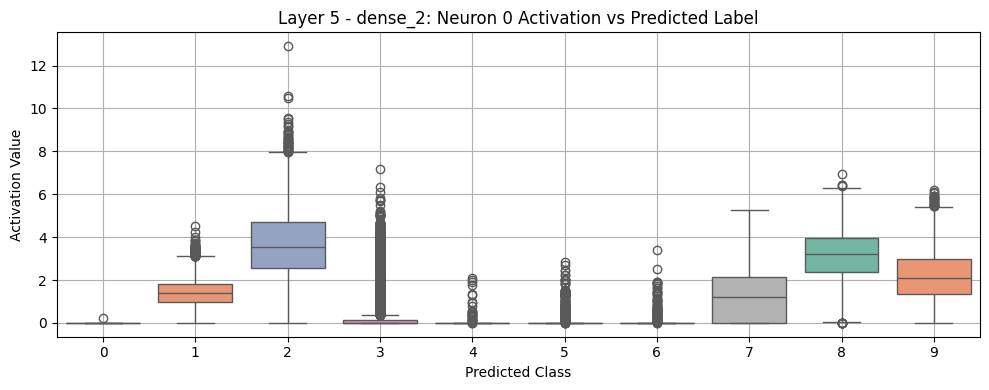

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


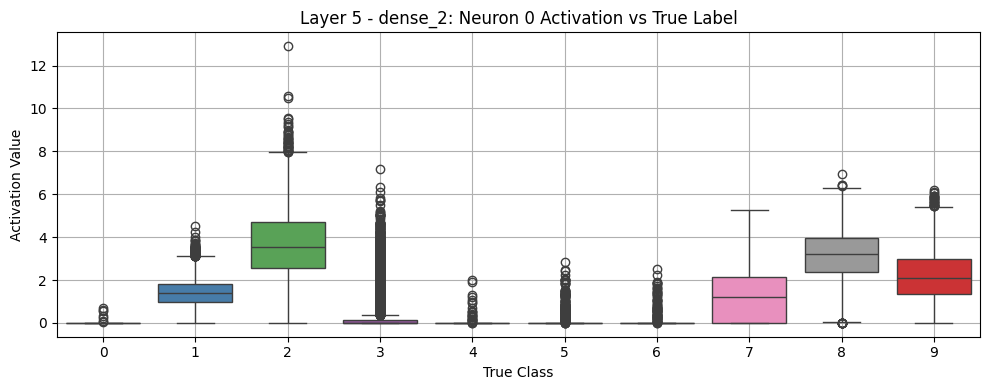

Skipping output layer: dense_3 (shape (55000, 10))


In [108]:
from tensorflow.keras import models
from tensorflow.keras.models import Model
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set this to your actual training data
# train_images = ...
# train_labels = ...

# If train_labels is one-hot, convert to integers
if train_labels.ndim > 1:
    true_labels = np.argmax(train_labels, axis=1)
else:
    true_labels = train_labels

# Create a model that outputs all layers
layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers in the model.")

# Get the activations for each layer (list of arrays)
activations = activation_model.predict(train_images)

# Get final predictions
pred_classes = model.predict(train_images).argmax(axis=1)

# Loop over each layer and generate boxplot for neuron 0
for i, activation in enumerate(activations):
    layer_name = model.layers[i].name
    layer_output = activation

    # Skip if output is 2D (final softmax layer) or has only 10 units
    if layer_output.shape[1] <= 10:
        print(f"Skipping output layer: {layer_name} (shape {layer_output.shape})")
        continue

    print(f"\n🔍 Layer {i+1} - {layer_name}: shape {layer_output.shape}")
    neuron_0_activation = layer_output[:, 0]  # Only neuron 0

    # Build DataFrame comparing neuron output vs both predicted & true class
    boxplot_df = pd.DataFrame({
        'act_value': neuron_0_activation,
        'predicted_label': pred_classes,
        'true_label': true_labels
    })

    # Plot 1: Grouped by predicted label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs Predicted Label')
    plt.xlabel('Predicted Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot 2: Grouped by true label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs True Label')
    plt.xlabel('True Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Experiment 7 Deep Network + Dropout

In [111]:
import tensorflow_addons as tfa  # Make sure to install this if not already
keras.backend.clear_session()
model = models.Sequential()
model.add(layers.Dense(128, activation='relu', input_shape=(784,)))
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(32, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))

optimizer = tfa.optimizers.AdamW(learning_rate=0.001, weight_decay=1e-4)

model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow_addons/utils/tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


Epoch 1/30
   8/1719 [..............................] - ETA: 13s - loss: 2.2005 - accuracy: 0.2148 

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 14s 8ms/step - loss: 0.2661 - accuracy: 0.9215 - val_loss: 0.1417 - val_accuracy: 0.9572
Epoch 2/30
1719/1719 [==============================] - 14s 8ms/step - loss: 0.1207 - accuracy: 0.9634 - val_loss: 0.1210 - val_accuracy: 0.9634
Epoch 3/30
1719/1719 [==============================] - 13s 8ms/step - loss: 0.0923 - accuracy: 0.9715 - val_loss: 0.0993 - val_accuracy: 0.9704
Epoch 4/30
1719/1719 [==============================] - 13s 8ms/step - loss: 0.0754 - accuracy: 0.9765 - val_loss: 0.1001 - val_accuracy: 0.9704
Epoch 5/30
1719/1719 [==============================] - 13s 8ms/step - loss: 0.0651 - accuracy: 0.9797 - val_loss: 0.0850 - val_accuracy: 0.9762
Epoch 6/30
1719/1719 [==============================] - 14s 8ms/step - loss: 0.0581 - accuracy: 0.9817 - val_loss: 0.0843 - val_accuracy: 0.9772
Epoch 7/30
1719/1719 [==============================] - 13s 8ms/step - loss: 0.0520 - accuracy: 0.9834 - val_loss: 0.0950 - val_accuracy: 0.9

In [112]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'test acc: {test_acc}, test loss: {test_loss}')
history_dict = history.history
history_dict.keys()

313/313 [==============================] - 1s 3ms/step - loss: 0.0853 - accuracy: 0.9766
test acc: 0.9765999913215637, test loss: 0.08532200008630753


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

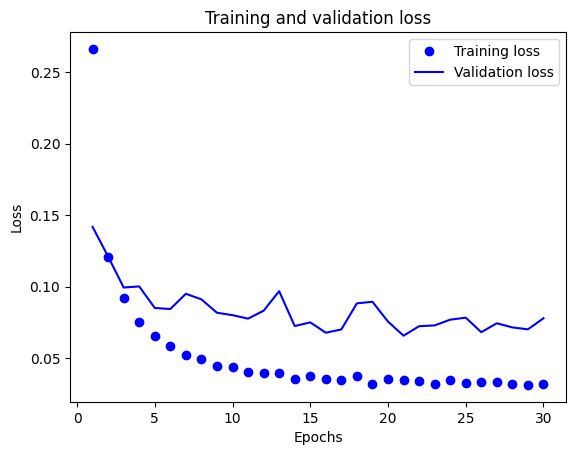

In [113]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

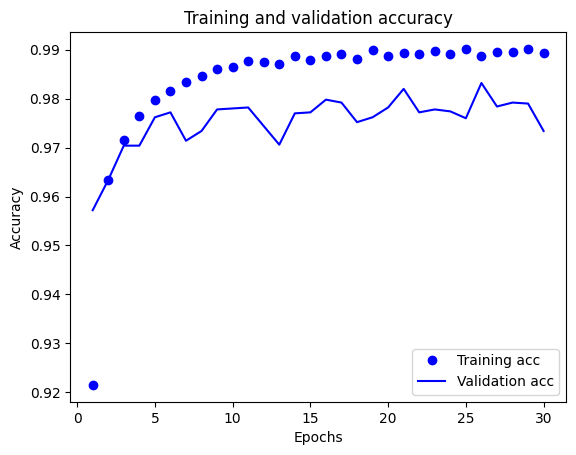

In [114]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [115]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 4 layers


[<KerasTensor: shape=(None, 128) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense_1')>,
 <KerasTensor: shape=(None, 32) dtype=float32 (created by layer 'dense_2')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_3')>]

There are 4 layers in the model.
1719/1719 [==============================] - 2s 1ms/step

🔍 Layer 1 - dense: shape (55000, 128)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


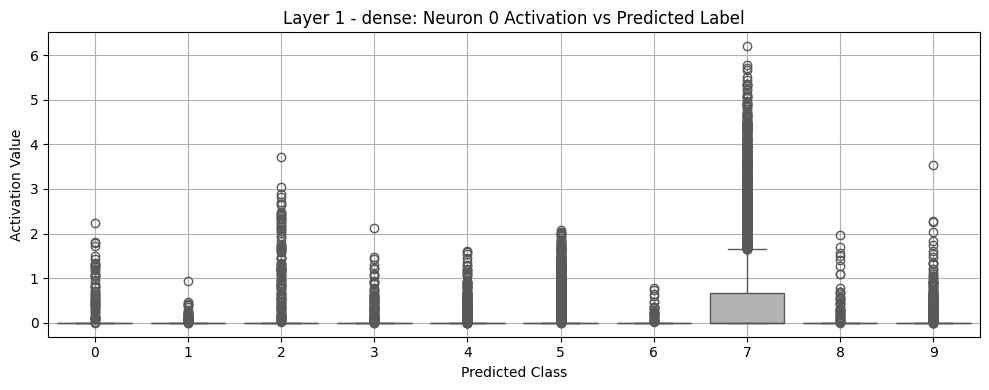

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


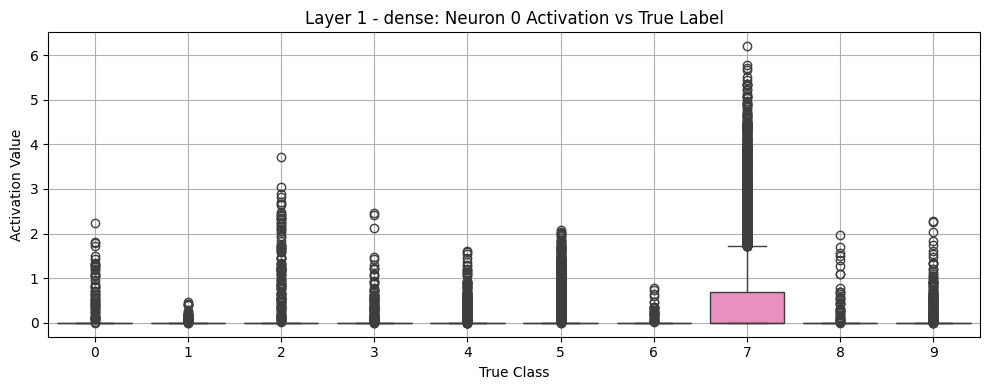

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 2 - dense_1: shape (55000, 64)


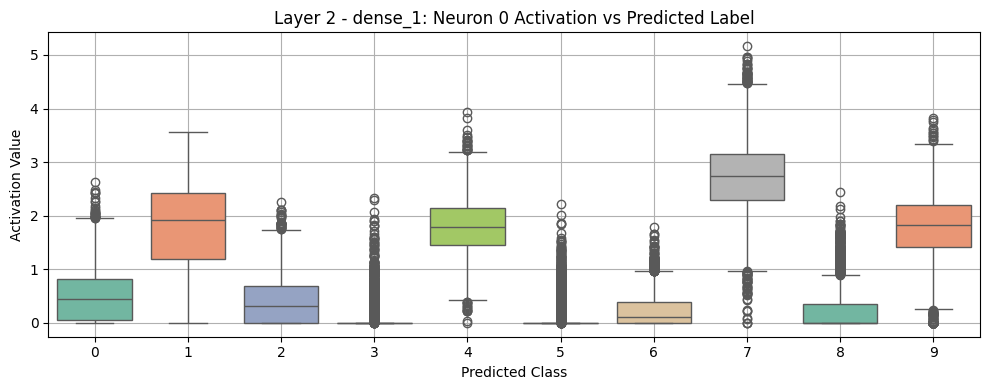

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


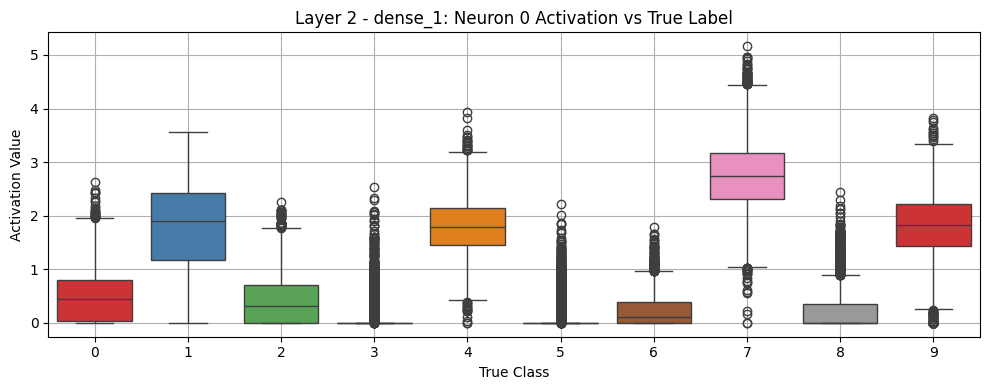

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 3 - dense_2: shape (55000, 32)


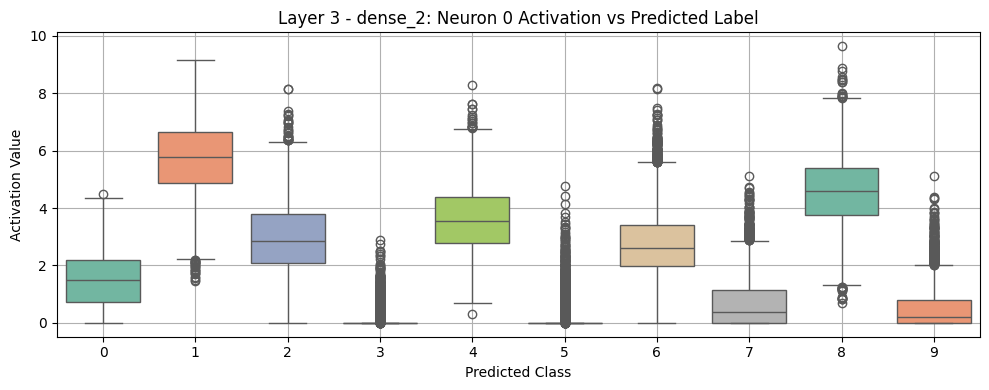

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


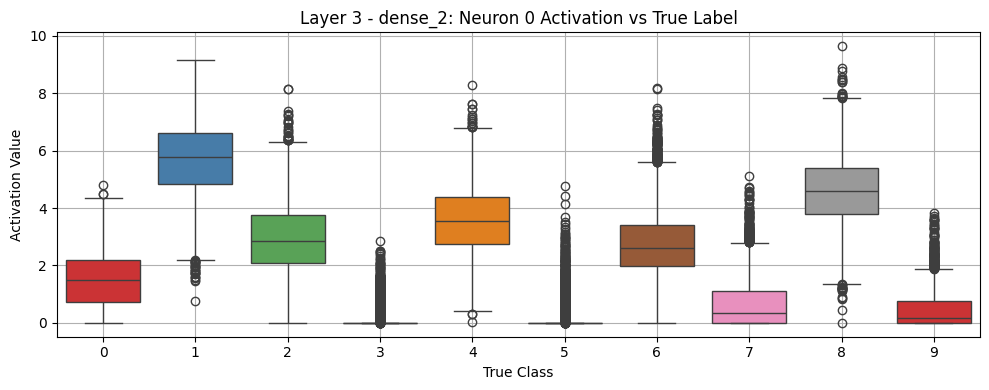

Skipping output layer: dense_3 (shape (55000, 10))


In [116]:
from tensorflow.keras import models
from tensorflow.keras.models import Model
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set this to your actual training data
# train_images = ...
# train_labels = ...

# If train_labels is one-hot, convert to integers
if train_labels.ndim > 1:
    true_labels = np.argmax(train_labels, axis=1)
else:
    true_labels = train_labels

# Create a model that outputs all layers
layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers in the model.")

# Get the activations for each layer (list of arrays)
activations = activation_model.predict(train_images)

# Get final predictions
pred_classes = model.predict(train_images).argmax(axis=1)

# Loop over each layer and generate boxplot for neuron 0
for i, activation in enumerate(activations):
    layer_name = model.layers[i].name
    layer_output = activation

    # Skip if output is 2D (final softmax layer) or has only 10 units
    if layer_output.shape[1] <= 10:
        print(f"Skipping output layer: {layer_name} (shape {layer_output.shape})")
        continue

    print(f"\n🔍 Layer {i+1} - {layer_name}: shape {layer_output.shape}")
    neuron_0_activation = layer_output[:, 0]  # Only neuron 0

    # Build DataFrame comparing neuron output vs both predicted & true class
    boxplot_df = pd.DataFrame({
        'act_value': neuron_0_activation,
        'predicted_label': pred_classes,
        'true_label': true_labels
    })

    # Plot 1: Grouped by predicted label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs Predicted Label')
    plt.xlabel('Predicted Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot 2: Grouped by true label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs True Label')
    plt.xlabel('True Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Experiment 8 Deep Network + Dropout

In [117]:
keras.backend.clear_session()
model = models.Sequential()
model.add(layers.Dense(64, activation='relu', input_shape=(784,)))
model.add(layers.BatchNormalization())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.BatchNormalization())
model.add(layers.Dense(10, activation='softmax'))

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)

model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
   5/1719 [..............................] - ETA: 25s - loss: 2.5947 - accuracy: 0.1437 

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 31s 18ms/step - loss: 0.2876 - accuracy: 0.9126 - val_loss: 0.1415 - val_accuracy: 0.9594
Epoch 2/30
1719/1719 [==============================] - 26s 15ms/step - loss: 0.1519 - accuracy: 0.9533 - val_loss: 0.1043 - val_accuracy: 0.9692
Epoch 3/30
1719/1719 [==============================] - 25s 15ms/step - loss: 0.1207 - accuracy: 0.9622 - val_loss: 0.0906 - val_accuracy: 0.9732
Epoch 4/30
1719/1719 [==============================] - 26s 15ms/step - loss: 0.1010 - accuracy: 0.9687 - val_loss: 0.0904 - val_accuracy: 0.9760
Epoch 5/30
1719/1719 [==============================] - 25s 15ms/step - loss: 0.0882 - accuracy: 0.9726 - val_loss: 0.0853 - val_accuracy: 0.9756
Epoch 6/30
1719/1719 [==============================] - 26s 15ms/step - loss: 0.0845 - accuracy: 0.9724 - val_loss: 0.0893 - val_accuracy: 0.9736
Epoch 7/30
1719/1719 [==============================] - 26s 15ms/step - loss: 0.0743 - accuracy: 0.9763 - val_loss: 0.0837 - val_accura

In [118]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f'test acc: {test_acc}, test loss: {test_loss}')
history_dict = history.history
history_dict.keys()

 23/313 [=>............................] - ETA: 1s - loss: 0.0756 - accuracy: 0.9796

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


313/313 [==============================] - 1s 4ms/step - loss: 0.0803 - accuracy: 0.9798
test acc: 0.9797999858856201, test loss: 0.0802767425775528


dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

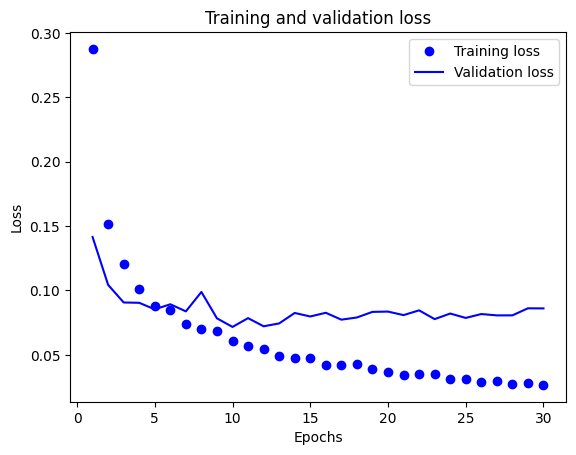

In [119]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

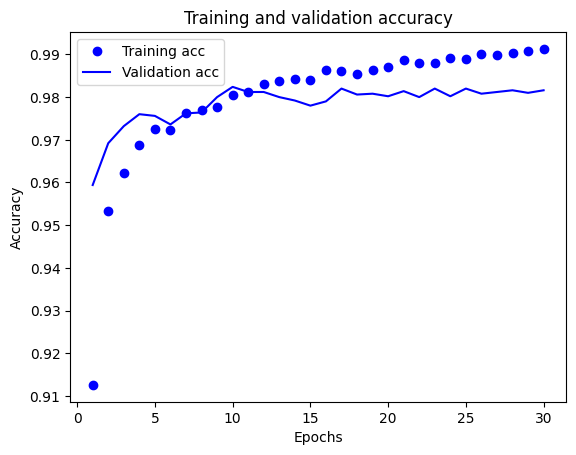

In [120]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [121]:
from tensorflow.keras import models

# Extracts the outputs of the 2 layers:
layer_outputs = [layer.output for layer in model.layers]

# Creates a model that will return these outputs, given the model input:
activation_model = models.Model(inputs=model.inputs, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers")
layer_outputs # description of the layers

There are 7 layers


[<KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'batch_normalization')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense_1')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'batch_normalization_1')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'dense_2')>,
 <KerasTensor: shape=(None, 64) dtype=float32 (created by layer 'batch_normalization_2')>,
 <KerasTensor: shape=(None, 10) dtype=float32 (created by layer 'dense_3')>]

There are 7 layers in the model.
1719/1719 [==============================] - 4s 2ms/step

🔍 Layer 1 - dense: shape (55000, 64)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


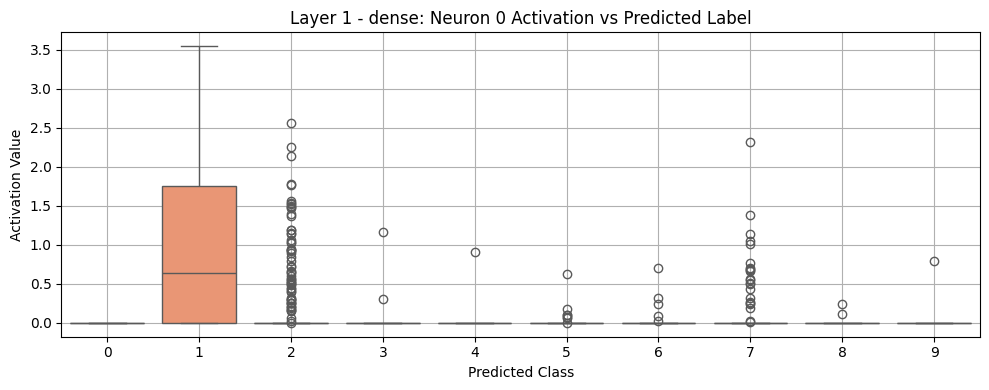

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


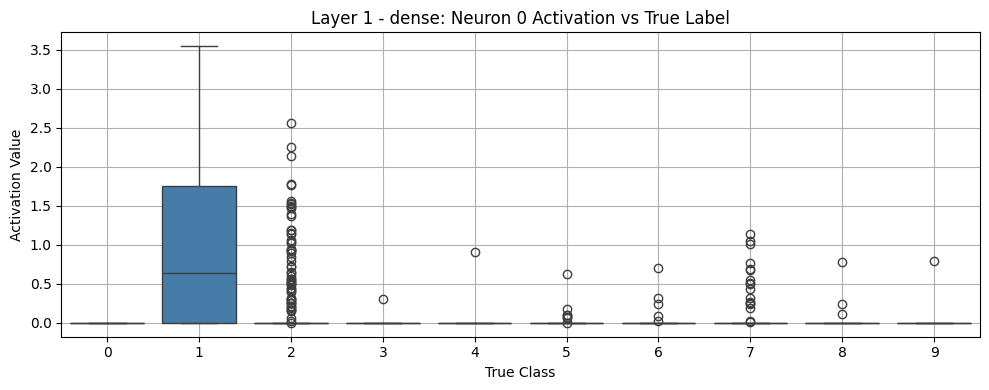

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 2 - batch_normalization: shape (55000, 64)


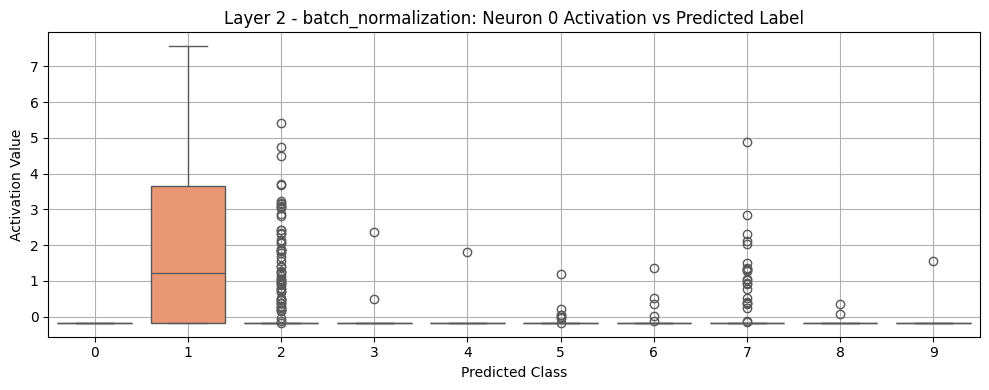

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


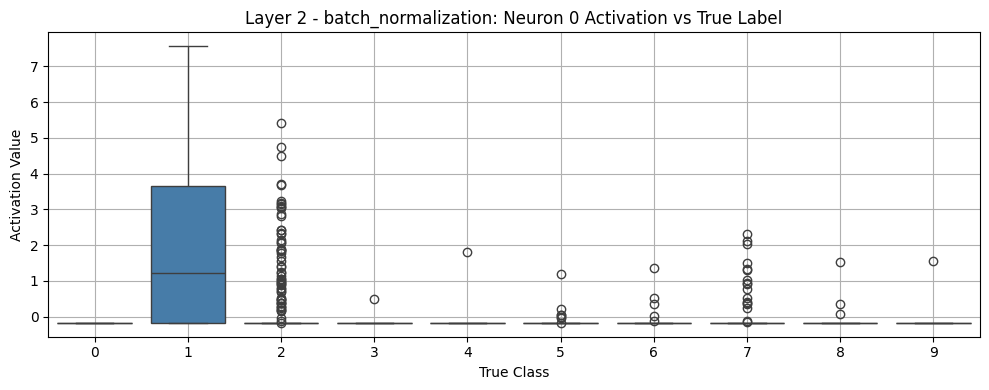

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 3 - dense_1: shape (55000, 64)


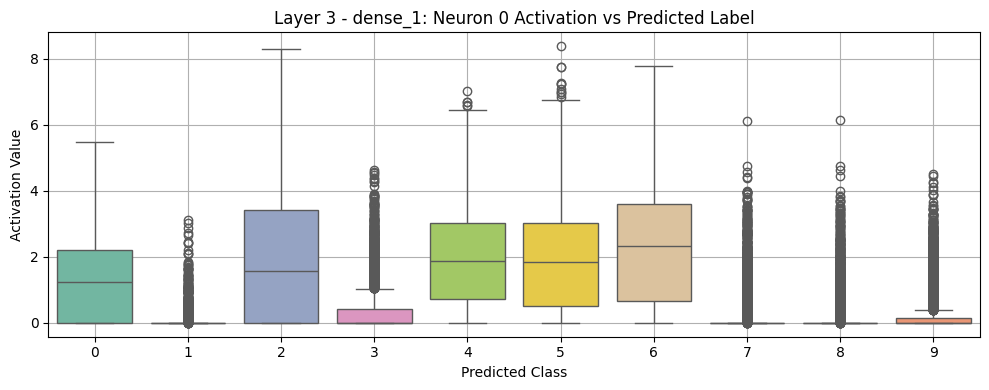

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


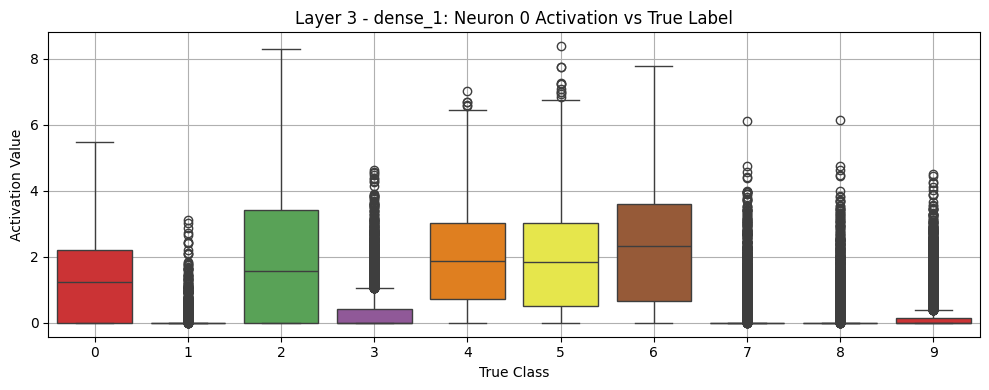

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 4 - batch_normalization_1: shape (55000, 64)


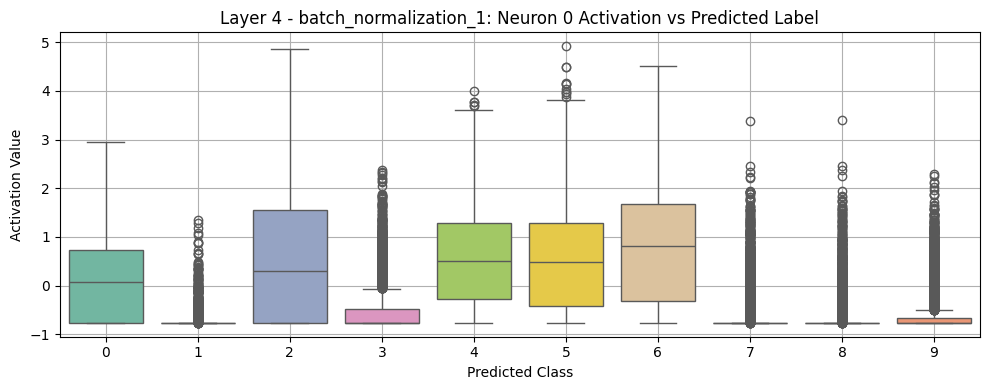

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


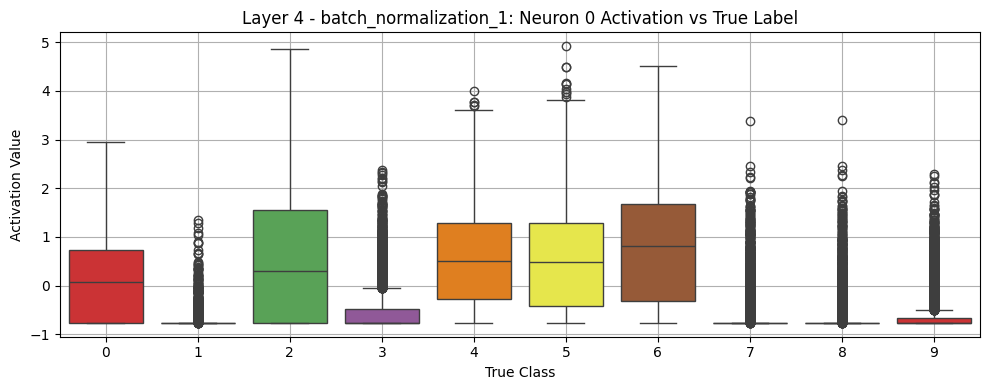


🔍 Layer 5 - dense_2: shape (55000, 64)


/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")


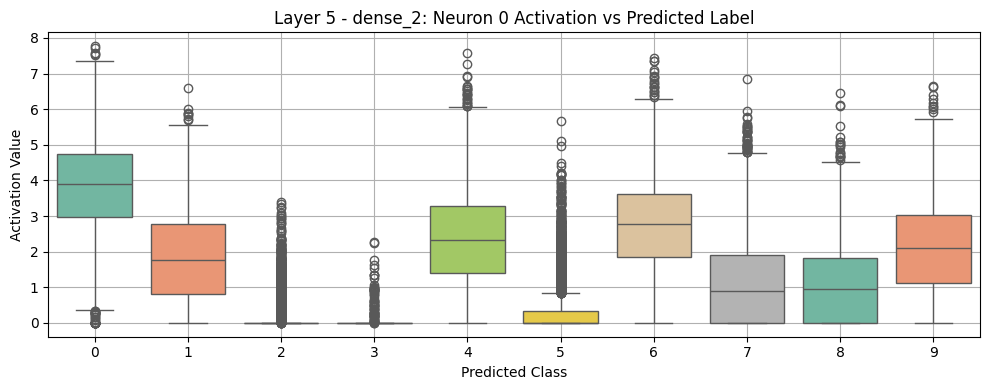

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


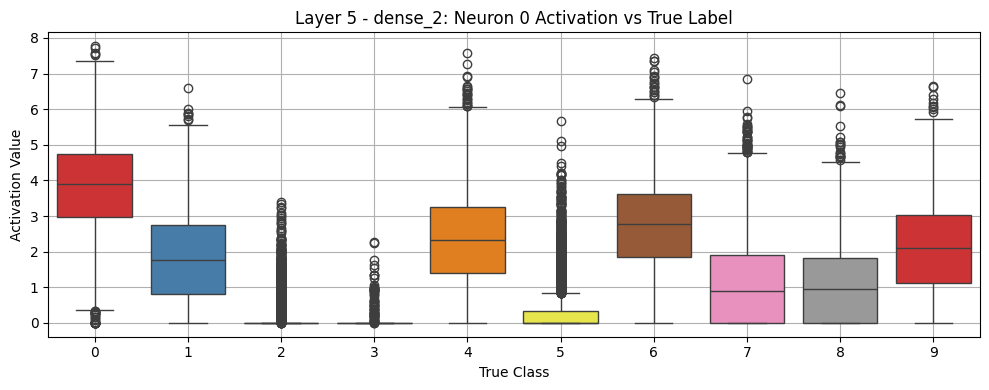

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")



🔍 Layer 6 - batch_normalization_2: shape (55000, 64)


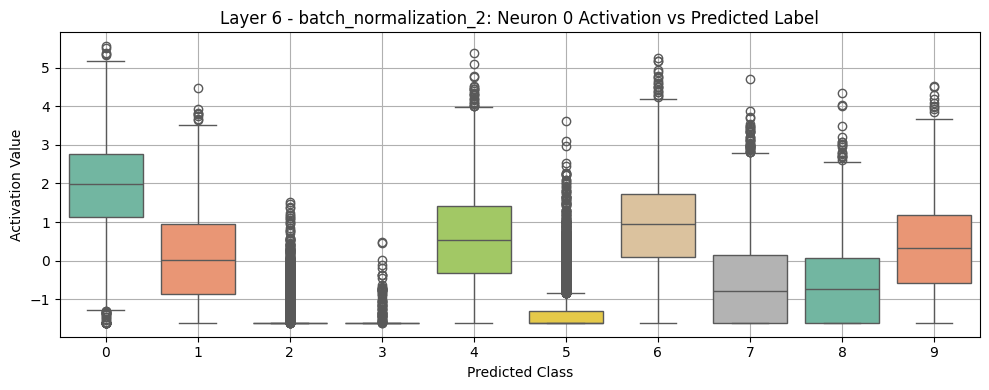

/var/folders/xc/3wsqwp_x79lbx1l9yz7pgf780000gn/T/ipykernel_80781/713611740.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")


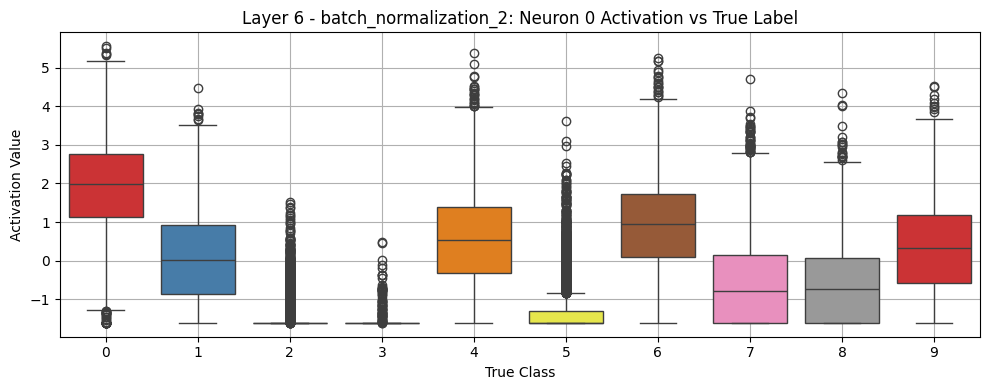

Skipping output layer: dense_3 (shape (55000, 10))


In [122]:
from tensorflow.keras import models
from tensorflow.keras.models import Model
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set this to your actual training data
# train_images = ...
# train_labels = ...

# If train_labels is one-hot, convert to integers
if train_labels.ndim > 1:
    true_labels = np.argmax(train_labels, axis=1)
else:
    true_labels = train_labels

# Create a model that outputs all layers
layer_outputs = [layer.output for layer in model.layers]
activation_model = Model(inputs=model.input, outputs=layer_outputs)

print(f"There are {len(layer_outputs)} layers in the model.")

# Get the activations for each layer (list of arrays)
activations = activation_model.predict(train_images)

# Get final predictions
pred_classes = model.predict(train_images).argmax(axis=1)

# Loop over each layer and generate boxplot for neuron 0
for i, activation in enumerate(activations):
    layer_name = model.layers[i].name
    layer_output = activation

    # Skip if output is 2D (final softmax layer) or has only 10 units
    if layer_output.shape[1] <= 10:
        print(f"Skipping output layer: {layer_name} (shape {layer_output.shape})")
        continue

    print(f"\n🔍 Layer {i+1} - {layer_name}: shape {layer_output.shape}")
    neuron_0_activation = layer_output[:, 0]  # Only neuron 0

    # Build DataFrame comparing neuron output vs both predicted & true class
    boxplot_df = pd.DataFrame({
        'act_value': neuron_0_activation,
        'predicted_label': pred_classes,
        'true_label': true_labels
    })

    # Plot 1: Grouped by predicted label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='predicted_label', y='act_value', data=boxplot_df, palette="Set2")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs Predicted Label')
    plt.xlabel('Predicted Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Plot 2: Grouped by true label
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='true_label', y='act_value', data=boxplot_df, palette="Set1")
    plt.title(f'Layer {i+1} - {layer_name}: Neuron 0 Activation vs True Label')
    plt.xlabel('True Class')
    plt.ylabel('Activation Value')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

Experiment 9 -PCA

In [123]:
from tensorflow.keras import models
from tensorflow.keras import layers

model = models.Sequential()
model.add(layers.Dense(85, activation='relu', input_shape=(28 * 28,)))
model.add(layers.Dense(10, activation='softmax'))

In [124]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 85)                66725     
                                                                 
 dense_5 (Dense)             (None, 10)                860       
                                                                 
Total params: 67585 (264.00 KB)
Trainable params: 67585 (264.00 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [125]:
model.compile(optimizer='rmsprop',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])

In [126]:
history = model.fit(train_images, train_labels, epochs=30,
                    validation_data=(val_images, val_labels))

Epoch 1/30
  16/1719 [..............................] - ETA: 12s - loss: 1.7453 - accuracy: 0.4902

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 13s 7ms/step - loss: 0.2884 - accuracy: 0.9178 - val_loss: 0.1547 - val_accuracy: 0.9568
Epoch 2/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.1418 - accuracy: 0.9581 - val_loss: 0.1172 - val_accuracy: 0.9664
Epoch 3/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.1061 - accuracy: 0.9694 - val_loss: 0.0919 - val_accuracy: 0.9730
Epoch 4/30
1719/1719 [==============================] - 13s 7ms/step - loss: 0.0868 - accuracy: 0.9746 - val_loss: 0.0890 - val_accuracy: 0.9736
Epoch 5/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.0756 - accuracy: 0.9782 - val_loss: 0.0909 - val_accuracy: 0.9734
Epoch 6/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.0652 - accuracy: 0.9810 - val_loss: 0.0920 - val_accuracy: 0.9752
Epoch 7/30
1719/1719 [==============================] - 12s 7ms/step - loss: 0.0576 - accuracy: 0.9835 - val_loss: 0.1013 - val_accuracy: 0.9

In [127]:
hist_dict = history.history
hist_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [128]:
print(f'''acc: {hist_dict['accuracy'][-1]:.4}, val acc: {hist_dict['val_accuracy'][-1]:.4},
loss: {hist_dict['loss'][-1]:.4}, val loss: {hist_dict['val_loss'][-1]:.4}''')

acc: 0.9977, val acc: 0.9718,
loss: 0.009487, val loss: 0.1703


In [129]:
test_loss, test_acc = model.evaluate(test_images, test_labels)

313/313 [==============================] - 1s 3ms/step - loss: 0.1578 - accuracy: 0.9752


In [130]:
print(f'test acc: {test_acc}, test loss: {test_loss}')

test acc: 0.9751999974250793, test loss: 0.1577884405851364


In [133]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
train_images_red = pca.fit_transform(train_images)
val_images_red = pca.transform(val_images)
test_images_red = pca.transform(test_images)

In [134]:
from tensorflow.keras import models
from tensorflow.keras import layers

model = models.Sequential()
model.add(layers.Dense(85, activation='relu', input_shape=(154,)))
model.add(layers.Dense(10, activation='softmax'))

# For use with non-categorical labels
model.compile(optimizer='rmsprop',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
history = model.fit(train_images_red, train_labels, epochs=30,
                    validation_data=(val_images_red, val_labels))

Epoch 1/30
   9/1719 [..............................] - ETA: 12s - loss: 2.1844 - accuracy: 0.2014 

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 17s 10ms/step - loss: 0.3493 - accuracy: 0.9026 - val_loss: 0.1606 - val_accuracy: 0.9548
Epoch 2/30
1719/1719 [==============================] - 11s 7ms/step - loss: 0.1413 - accuracy: 0.9584 - val_loss: 0.1176 - val_accuracy: 0.9666
Epoch 3/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.1010 - accuracy: 0.9704 - val_loss: 0.0948 - val_accuracy: 0.9716
Epoch 4/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.0779 - accuracy: 0.9774 - val_loss: 0.0865 - val_accuracy: 0.9754
Epoch 5/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.0628 - accuracy: 0.9818 - val_loss: 0.0825 - val_accuracy: 0.9752
Epoch 6/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.0520 - accuracy: 0.9850 - val_loss: 0.0825 - val_accuracy: 0.9762
Epoch 7/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.0429 - accuracy: 0.9881 - val_loss: 0.0815 - val_accuracy: 0.

In [135]:
hist_dict = history.history
hist_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [136]:
print(f'''acc: {hist_dict['accuracy'][-1]:.4}, val acc: {hist_dict['val_accuracy'][-1]:.4},
loss: {hist_dict['loss'][-1]:.4}, val loss: {hist_dict['val_loss'][-1]:.4}''')

acc: 0.9999, val acc: 0.9752,
loss: 0.0009672, val loss: 0.1532


In [137]:
test_loss, test_acc = model.evaluate(test_images_red, test_labels)

313/313 [==============================] - 1s 3ms/step - loss: 0.1720 - accuracy: 0.9752


In [138]:
print(f'test acc: {test_acc}, test loss: {test_loss}')

test acc: 0.9751999974250793, test loss: 0.1719917207956314


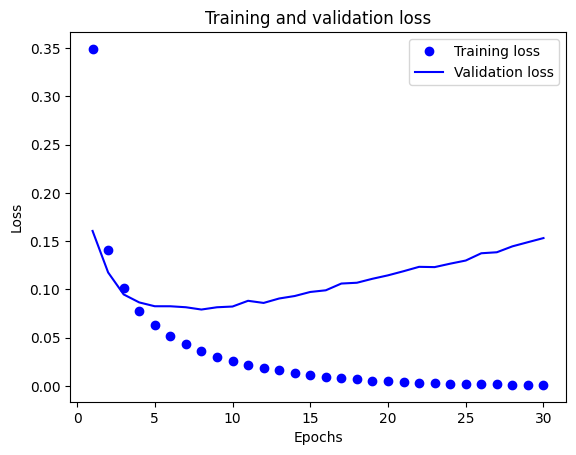

In [140]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

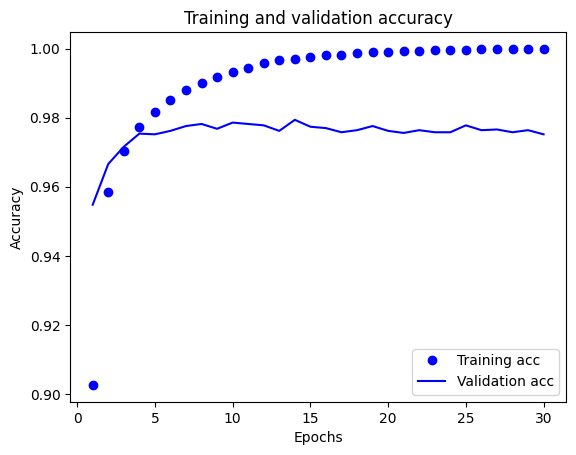

In [141]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

Experiment 10 random forest classifier

In [142]:
from sklearn.ensemble import RandomForestClassifier

rnd_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rnd_clf.fit(train_images,train_labels)

n = 70
imp_arr = rnd_clf.feature_importances_
idx = (-imp_arr).argsort()[:n]          # get the indices of the 70 "most important" features/pixels
len(idx)


from tensorflow.keras import models
from tensorflow.keras import layers

# Create training, validation and test images using just the 70 pixel locations obtained above
train_images_sm = train_images[:,idx]
val_images_sm = val_images[:,idx]
test_images_sm = test_images[:,idx]
train_images_sm.shape, val_images.shape, test_images_sm.shape # the reduced images have dimension 70



((55000, 70), (5000, 784), (10000, 70))

In [143]:
# to convert an index n, 0<= n < 784
def pair(n,size):
    x = n//size
    y = n%size
    return x,y

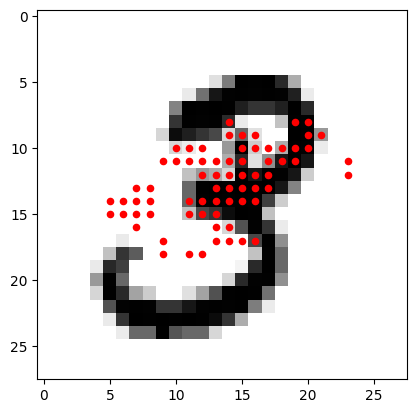

In [144]:
plt.imshow(train_images[1].reshape(28,28),cmap='binary')
x, y = np.array([pair(k,28) for k in idx]).T
plt.scatter(x,y,color='red',s=20)

In [145]:

model = models.Sequential()
model.add(layers.Dense(85, activation='relu', input_shape=(70,)))
model.add(layers.Dense(10, activation='softmax'))

# For use with non-categorical labels
model.compile(optimizer='rmsprop',
                loss='sparse_categorical_crossentropy',
                metrics=['accuracy'])
history = model.fit(train_images_sm, train_labels, epochs=30,
                    validation_data=(val_images_sm, val_labels))

Epoch 1/30
  19/1719 [..............................] - ETA: 9s - loss: 2.0213 - accuracy: 0.3240 

/Users/jck/anaconda3/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


1719/1719 [==============================] - 11s 6ms/step - loss: 0.6047 - accuracy: 0.8203 - val_loss: 0.4221 - val_accuracy: 0.8726
Epoch 2/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.3955 - accuracy: 0.8786 - val_loss: 0.3482 - val_accuracy: 0.8992
Epoch 3/30
1719/1719 [==============================] - 10s 6ms/step - loss: 0.3321 - accuracy: 0.8987 - val_loss: 0.3018 - val_accuracy: 0.9146
Epoch 4/30
1719/1719 [==============================] - 11s 6ms/step - loss: 0.2945 - accuracy: 0.9108 - val_loss: 0.2747 - val_accuracy: 0.9178
Epoch 5/30
1719/1719 [==============================] - 10s 6ms/step - loss: 0.2702 - accuracy: 0.9190 - val_loss: 0.2631 - val_accuracy: 0.9262
Epoch 6/30
1719/1719 [==============================] - 10s 6ms/step - loss: 0.2531 - accuracy: 0.9236 - val_loss: 0.2622 - val_accuracy: 0.9236
Epoch 7/30
1719/1719 [==============================] - 10s 6ms/step - loss: 0.2398 - accuracy: 0.9279 - val_loss: 0.2495 - val_accuracy: 0.9

In [146]:
hist_dict = history.history
hist_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

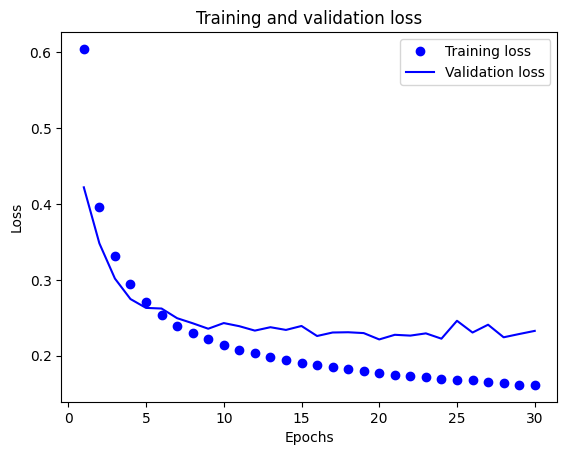

In [147]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

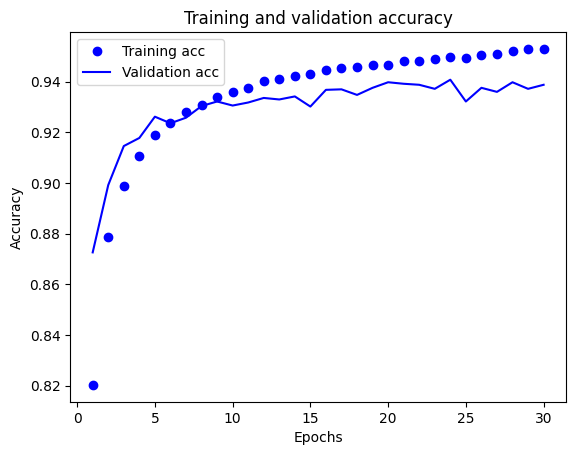

In [148]:
plt.clf()   # clear figure
acc_values = history_dict['accuracy']
# val_acc_values = history_dict['val_acc']

plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

In [1]:
!jupyter nbconvert --to pdf MSDS458_Assignment1_Kwok.ipynb

[NbConvertApp] Converting notebook MSDS458_Assignment1_Kwok.ipynb to pdf
[NbConvertApp] Support files will be in MSDS458_Assignment1_Kwok_files/
[NbConvertApp] Making directory ./MSDS458_Assignment1_Kwok_files
[NbConvertApp] Writing 320993 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 7490068 bytes to MSDS458_Assignment1_Kwok.pdf


In [3]:
!jupyter nbconvert --to html MSDS458_Assignment1_Kwok.ipynb

[NbConvertApp] Converting notebook MSDS458_Assignment1_Kwok.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 89 image(s).
[NbConvertApp] Writing 12657386 bytes to MSDS458_Assignment1_Kwok.html
